<a href="https://colab.research.google.com/github/dinesh-kn-0380/-Kidney-Abnormality-Detection-from-CT-RA2311026050010/blob/main/RA2311026050010_PS21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PS-21 — Kidney Abnormality Detection from CT
**Challenge Based Learning (CBL) — Image Classification Challenge · Deep Learning**

| Field | Value |
|---|---|
| Student name | Dinesh Kumar N |
| Register number | RA2311026050010 |
| Section | AIML-B |
| Institution | SRM Institute of Science and Technology, Tiruchirappalli |
| Department | CSE — Artificial Intelligence and Machine Learning |
| Problem | PS-21 — Kidney Abnormality Detection from CT |

> **Evidence rule.** Every number, table and figure in this notebook and in the report is produced by the code below
> from the real dataset. Nothing is typed in by hand. If a cell has not been run, its output is empty — it is never pre-filled.

## 1. Problem statement and objectives
**Official PS-21 text (CBL document, Part B, p.10):** *Classify kidney CT slices as normal or showing a cyst, stone or tumour. Many slices come from the same patient study, so a random split can leak information; discuss how this affects your accuracy. Stone is the smallest class, so report its recall separately.*

**Classes (fixed order used everywhere):** `Normal, Cyst, Stone, Tumour`

**Objectives**
1. Build a CNN (transfer learning, MobileNetV2) that classifies a CT slice into the four classes.
2. Split data with a fixed seed into 80 / 10 / 10 train / validation / test and **address leakage explicitly** (Section 9–11).
3. Handle class imbalance (class-weighted loss from training labels only) and report **Stone recall separately**.
4. Evaluate **once** on the held-out test set: accuracy, per-class precision/recall/F1, macro-F1, confusion matrix.
5. Show ≥ 4 misclassified test images with an explanation; add one justified extra analysis (class-weighted vs unweighted, plus Grad-CAM).

**Success metric.** Plain accuracy is not enough because classes are imbalanced. The judging metrics are **macro-F1** (every class counts equally) and **Stone recall** (a missed stone is the costly error), with accuracy reported alongside.

## 2. Environment and dependency setup

In [1]:
# Select Runtime > Change runtime type > T4 GPU before running (CPU also works, but is much slower).
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle", "python-docx", "reportlab", "pypdf", "seaborn"], check=False)
print("Dependencies ready.")

Dependencies ready.


## 3. Reproducibility settings and configuration
All tunable settings live in this one cell. The report is generated from what is actually used here (saved to `PS21_results.json`).

In [2]:
import os, sys, time, json, re, math, random, shutil, zipfile, platform, datetime, warnings, hashlib, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ---------------- student details (used in every output) ----------------
STUDENT = dict(name="Dinesh Kumar N", reg="RA2311026050010", section="AIML-B",
               institution="SRM Institute of Science and Technology, Tiruchirappalli",
               department="CSE - Artificial Intelligence and Machine Learning",
               subject="Deep Learning", ps="PS-21", title="Kidney Abnormality Detection from CT")
GITHUB_URL = ""   # paste your repository link here AFTER you publish it (never invent one)

# ---------------- experiment configuration ----------------
SEED          = 42
CLASS_NAMES   = ["Normal", "Cyst", "Stone", "Tumour"]       # fixed order everywhere
IMG_SIZE      = 160          # MobileNetV2 supports 160; lighter than 224 for free Colab
BATCH_SIZE    = 32
LR_HEAD       = 1e-3         # phase 1: classifier head only (backbone frozen)
EPOCHS_HEAD   = 8            # maximum; early stopping may end sooner
LR_FINETUNE   = 1e-5         # phase 2: small LR for gentle fine-tuning
EPOCHS_FT     = 5            # maximum
FT_LAST_LAYERS = 30          # last N backbone layers unfrozen in phase 2 (BatchNorm kept frozen)
DROPOUT       = 0.3
ES_PATIENCE   = 3            # early stopping patience on val_loss
RUN_COMPARISON = True        # also train an UNWEIGHTED baseline for the class-weight comparison
NEAR_DUP_BITS_OPTIONS = [24, 16, 8, 0]   # Hamming-distance thresholds (of 256 hash bits) tried in order
MAX_GROUP_FRACTION = 0.05    # a near-duplicate group may not exceed 5% of the dataset
GROUP_REGEX   = None         # if filenames DO contain a patient/study id, set e.g. r"patient[_-]?(\d+)"
KAGGLE_SLUG   = "nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone"
DATA_DIR      = None         # set to a folder path if your faculty gave you a local copy (e.g. on Drive)

# Developer smoke-test switch used only to test the code on tiny synthetic data. LEAVE UNSET.
DRY_RUN = os.environ.get("PS21_DRY_RUN") == "1"

IN_COLAB = "google.colab" in sys.modules
OUT_DIR = Path("/content/PS21_outputs") if IN_COLAB else Path("PS21_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

import tensorflow as tf
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

import sklearn, PIL, scipy
VERSIONS = dict(python=platform.python_version(), tensorflow=tf.__version__, keras=tf.keras.__version__,
                numpy=np.__version__, pandas=pd.__version__, scikit_learn=sklearn.__version__,
                pillow=PIL.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("Library versions:", json.dumps(VERSIONS, indent=1))
print("GPU available:", [g.name for g in GPUS] if GPUS else "NO (running on CPU - training will be slow)")
print("Seed:", SEED, "| Output folder:", OUT_DIR.resolve())
if DRY_RUN: print("*** DRY_RUN smoke-test mode: results are NOT real experimental results ***")

Library versions: {
 "python": "3.13.16",
 "tensorflow": "2.21.0",
 "keras": "3.13.2",
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "scikit_learn": "1.6.1",
 "pillow": "11.3.0",
 "scipy": "1.16.3",
 "matplotlib": "3.10.0"
}
GPU available: ['/physical_device:GPU:0']
Seed: 42 | Output folder: /content/PS21_outputs


## 4. Dataset download or upload
**Dataset (specified by PS-21):** CT Kidney Dataset — https://www.kaggle.com/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone

The cell below tries, in order: **(a)** a local copy if `DATA_DIR` is set (e.g. the copy provided by your faculty), **(b)** the Kaggle API (token from Colab Secrets, or pasted into a **hidden** prompt), **(c)** a manual ZIP upload. If it finds a half-downloaded folder (missing classes) it deletes it and downloads again.

**Getting a Kaggle token safely:** Kaggle → profile picture → *Settings* → *API* → *Create New Token*. Either add it in Colab's 🔑 **Secrets** panel as `KAGGLE_API_TOKEN` (enable notebook access), or just run the cell and paste the token into the hidden box that appears. **Never type the token into a code cell** — it would be saved in the notebook and published to GitHub.

In [3]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=False)
import getpass

def get_kaggle_credentials():
    # 1) Colab secrets (if you added them), 2) environment, 3) hidden prompt. Never printed, never saved in the notebook.
    if IN_COLAB:
        try:
            from google.colab import userdata
            for k in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
                try: os.environ[k] = userdata.get(k)
                except Exception: pass
        except Exception: pass
    have = bool(os.environ.get("KAGGLE_API_TOKEN") or (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")))
    have = have or (Path.home() / ".kaggle" / "kaggle.json").exists() or (Path.home() / ".kaggle" / "access_token").exists()
    if not have:
        tok = getpass.getpass("Paste your Kaggle API token (hidden, press Enter to skip): ").strip()
        if tok:
            os.environ["KAGGLE_API_TOKEN"] = tok; have = True
    return have

def try_kaggle_download(dest):
    if not get_kaggle_credentials():
        print("No Kaggle credentials provided."); return False
    r = subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_SLUG, "-p", str(dest), "--unzip"],
                       capture_output=True, text=True)
    print("Kaggle download return code:", r.returncode)
    if r.returncode != 0:
        print("Kaggle download failed:", (r.stderr or r.stdout)[-400:])
    return r.returncode == 0

def manual_upload(dest):
    # Fallback: upload the dataset ZIP by hand (slow for large files; prefer the Kaggle route or Google Drive).
    if not IN_COLAB:
        print("Not in Colab: place the extracted dataset folder somewhere and set DATA_DIR above."); return False
    from google.colab import files
    print("Upload the dataset ZIP file now ...")
    up = files.upload()
    for name in up:
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(name) as z: z.extractall(dest)
            print("Extracted", name); return True
    print("No ZIP found in the upload."); return False

def classes_present(root):
    # Which of the four class folders exist (with at least one image) under root?
    found = set()
    for p in Path(root).rglob("*"):
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
            c = p.parent.name.strip().lower()
            if c in ("normal", "cyst", "stone", "tumor", "tumour"): found.add("tumour" if c == "tumor" else c)
    return found

DATA_ROOT = Path("/content/kidney_ct") if IN_COLAB else Path("kidney_ct")
if DRY_RUN:
    DATA_ROOT = Path(os.environ.get("PS21_DRY_DIR", "kidney_ct_synthetic"))
elif DATA_DIR and Path(DATA_DIR).exists():
    DATA_ROOT = Path(DATA_DIR); print("Using local dataset copy:", DATA_ROOT)
else:
    if DATA_ROOT.exists() and any(DATA_ROOT.rglob("*")):
        have_cls = classes_present(DATA_ROOT)
        if have_cls >= {"normal", "cyst", "stone", "tumour"}:
            print("Dataset already present at", DATA_ROOT)
        else:
            print(f"Found an INCOMPLETE dataset folder (classes present: {sorted(have_cls)}). Deleting it and downloading again ...")
            shutil.rmtree(DATA_ROOT, ignore_errors=True)
    if not (DATA_ROOT.exists() and classes_present(DATA_ROOT) >= {"normal", "cyst", "stone", "tumour"}):
        DATA_ROOT.mkdir(parents=True, exist_ok=True)
        if not try_kaggle_download(DATA_ROOT):
            print("\n>>> Kaggle download unavailable. Falling back to manual upload (slow for large ZIP files).")
            manual_upload(DATA_ROOT)
print("DATA_ROOT =", DATA_ROOT.resolve())

Paste your Kaggle API token (hidden, press Enter to skip): ··········
Kaggle download return code: 0
DATA_ROOT = /content/kidney_ct


## 5. Dataset discovery and validation
The code does **not** assume a folder layout. It walks the extracted files, finds every image, and maps the *parent folder name* to a class. `Tumor` and `Tumour` are both mapped to **Tumour**. Every image is then decoded; unreadable files are listed and **excluded**. A perceptual hash is computed during the same pass (used later for near-duplicate leakage analysis).

In [4]:
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
FOLDER_TO_CLASS = {"normal": "Normal", "cyst": "Cyst", "stone": "Stone", "tumor": "Tumour", "tumour": "Tumour"}

rows, unmapped_dirs = [], {}
for p in DATA_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMG_EXT:
        cls = FOLDER_TO_CLASS.get(p.parent.name.strip().lower())
        if cls is None: unmapped_dirs[str(p.parent)] = unmapped_dirs.get(str(p.parent), 0) + 1
        else: rows.append((str(p), cls))

if not rows:
    raise SystemExit("DIAGNOSTIC: no images found under DATA_ROOT=%s.\n"
                     "Fix: set DATA_DIR (top of Section 3) to the folder that CONTAINS the class sub-folders "
                     "(Normal, Cyst, Stone, Tumor) or re-run the download/upload cell." % DATA_ROOT)
df = pd.DataFrame(rows, columns=["path", "class_name"]).sort_values("path").reset_index(drop=True)
print("Image files mapped to the 4 classes:", len(df))
if unmapped_dirs: print("Folders with images that were NOT mapped to a class (ignored):", unmapped_dirs)
print("Class folders used:"); print(df.assign(folder=df.path.map(lambda s: str(Path(s).parent))).groupby(["class_name", "folder"]).size())
missing = [c for c in CLASS_NAMES if c not in set(df.class_name)]
assert not missing, "DIAGNOSTIC: class folder(s) not found: %s - check folder names under %s" % (missing, DATA_ROOT)

# --- decode every image + 16x16 difference hash (256 bits) in one pass ---
def dhash_bits(img, n=16):
    g = img.convert("L").resize((n + 1, n), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).astype(np.uint8).ravel())   # 256 bits -> 32 bytes

def inspect(path):
    try:
        with Image.open(path) as im:
            im.load(); w, h = im.size
            return True, w, h, dhash_bits(im), ""
    except Exception as e:
        return False, 0, 0, None, repr(e)[:120]

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex: res = list(ex.map(inspect, df.path))
df["ok"] = [r[0] for r in res]; df["w"] = [r[1] for r in res]; df["h"] = [r[2] for r in res]
bad = df[~df.ok]
print(f"Decoded {len(df)} files in {time.time()-t0:.0f}s | unreadable: {len(bad)}")
if len(bad): print(bad[["path"]].assign(error=[res[i][4] for i in bad.index]).to_string())
HASHES = np.stack([r[3] for i, r in enumerate(res) if r[0]])
df = df[df.ok].drop(columns="ok").reset_index(drop=True)
N_UNREADABLE = int(len(bad))
df["label"] = df.class_name.map({c: i for i, c in enumerate(CLASS_NAMES)}).astype(int)
df["rel_path"] = df.path.map(lambda s: os.path.relpath(s, DATA_ROOT))
N_TOTAL = len(df)
print("\nUSABLE images (exact number used in this experiment):", N_TOTAL)
print("Image sizes (w x h) seen:", df.groupby(["w", "h"]).size().sort_values(ascending=False).head(5).to_dict())
if N_TOTAL != 12446:
    print(f"NOTE: the assignment quotes 12,446 images; the files actually found = {N_TOTAL}. All results use {N_TOTAL}.")

Image files mapped to the 4 classes: 12446
Class folders used:
class_name  folder                                                                                                       
Cyst        /content/kidney_ct/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst      3709
Normal      /content/kidney_ct/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Normal    5077
Stone       /content/kidney_ct/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Stone     1377
Tumour      /content/kidney_ct/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Tumor     2283
dtype: int64
Decoded 12446 files in 58s | unreadable: 0

USABLE images (exact number used in this experiment): 12446
Image sizes (w x h) seen: {(512, 512): 7709, (798, 646): 240, (804, 651): 179, (768, 622): 177, (840, 680): 171}


## 6. Class counts and class-distribution chart

class_name
Normal    5077
Cyst      3709
Stone     1377
Tumour    2283
Smallest class: Stone | imbalance ratio largest/smallest = 3.69


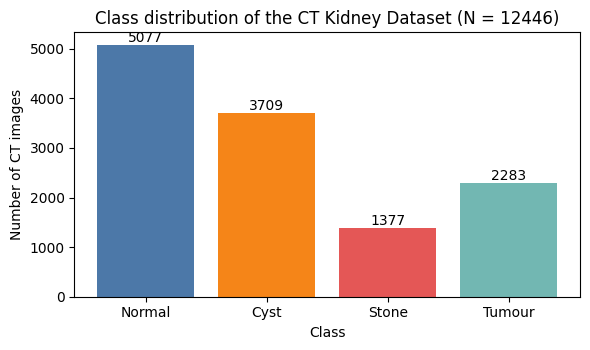

In [5]:
import seaborn as sns
counts = df.class_name.value_counts().reindex(CLASS_NAMES)
print(counts.to_string()); print("Smallest class:", counts.idxmin(), "| imbalance ratio largest/smallest = %.2f" % (counts.max() / counts.min()))
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(CLASS_NAMES, counts.values, color=["#4c78a8", "#f58518", "#e45756", "#72b7b2"])
for b, v in zip(bars, counts.values): ax.text(b.get_x() + b.get_width() / 2, v, f"{v}", ha="center", va="bottom", fontsize=10)
ax.set_xlabel("Class"); ax.set_ylabel("Number of CT images"); ax.set_title(f"Class distribution of the CT Kidney Dataset (N = {N_TOTAL})")
plt.tight_layout(); plt.savefig(OUT_DIR / "PS21_class_distribution.png", dpi=200); plt.show()

## 7. Representative images from each class

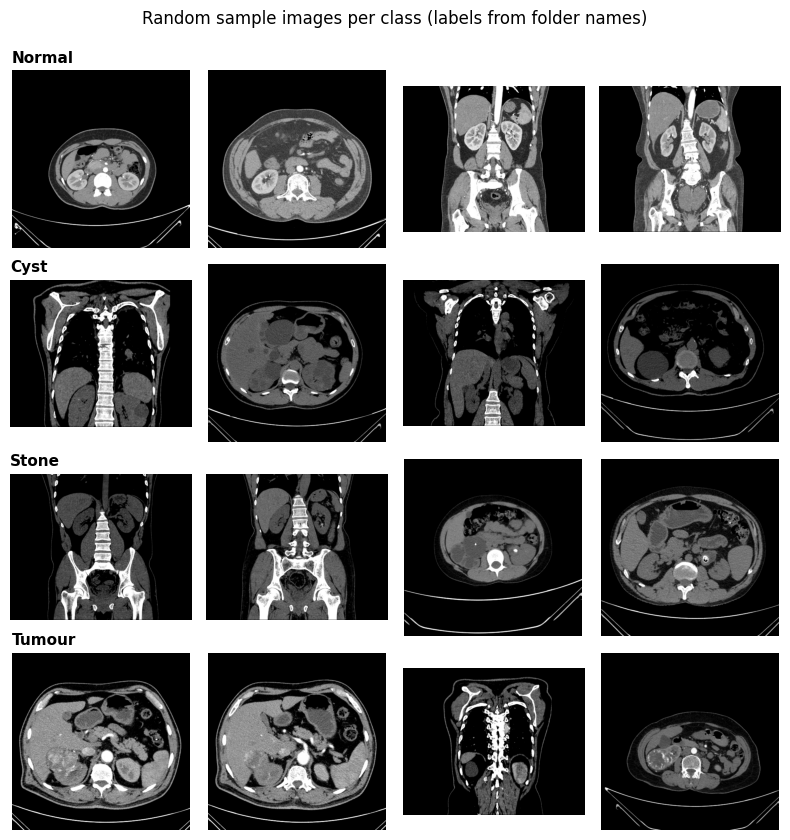

In [6]:
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(4, 4, figsize=(8, 8.4))
for r, c in enumerate(CLASS_NAMES):
    pick = rng.choice(df.index[df.class_name == c], 4, replace=False)
    for k, idx in enumerate(pick):
        axes[r, k].imshow(Image.open(df.path[idx]).convert("L"), cmap="gray"); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(f"{c}", loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Random sample images per class (labels from folder names)", y=0.995); plt.tight_layout()
plt.savefig(OUT_DIR / "PS21_sample_images.png", dpi=150); plt.show()

## 8. Patient / study identifier inspection
PS-21 warns that many slices come from the same patient study. A **patient-level split is only possible if a patient/study ID can be recovered**. The cell below searches file names and any metadata CSV for such identifiers. It does not assume the answer.

In [7]:
print("Example file names:"); print(df.path.map(lambda s: Path(s).name).sample(8, random_state=SEED).tolist())
ID_TOKENS = re.compile(r"(patient|pat[_-]?id|study|series|scan|subject|case|accession|mrn)", re.I)
name_hits = int(df.path.map(lambda s: bool(ID_TOKENS.search(Path(s).name))).sum())
print(f"\nFile names containing a patient/study/series-type token: {name_hits} of {N_TOTAL}")
meta_csvs = list(DATA_ROOT.rglob("*.csv")); meta_hits = []
for m in meta_csvs:
    try:
        cols = list(pd.read_csv(m, nrows=2).columns); print("Metadata file:", m.name, "| columns:", cols)
        meta_hits += [c for c in cols if ID_TOKENS.search(str(c))]
    except Exception as e: print("Could not read", m.name, e)
print("Metadata columns that look like patient/study IDs:", meta_hits or "none")
PATIENT_IDS_AVAILABLE = bool(GROUP_REGEX) or name_hits > 0.5 * N_TOTAL or bool(meta_hits)
if GROUP_REGEX: print("GROUP_REGEX is set -> patient/study ids will be parsed from file names.")
elif PATIENT_IDS_AVAILABLE:
    print("Possible ids found. Inspect them, then set GROUP_REGEX (Section 3) to a regex whose first group is the id and re-run.")
    PATIENT_IDS_AVAILABLE = False
else:
    print("\nCONCLUSION: no reliable patient/study identifier can be recovered from this copy of the dataset.")
    print("A true patient-level split is therefore NOT possible. Section 9 uses a near-duplicate-grouped split as the best available proxy.")

Example file names:
['Cyst- (1355).jpg', 'Cyst- (1220).jpg', 'Stone- (182).jpg', 'Cyst- (2286).jpg', 'Cyst- (999).jpg', 'Cyst- (2565).jpg', 'Tumor- (738).jpg', 'Stone- (283).jpg']

File names containing a patient/study/series-type token: 0 of 12446
Metadata file: kidneyData.csv | columns: ['Unnamed: 0', 'image_id', 'path', 'diag', 'target', 'Class']
Metadata columns that look like patient/study IDs: none

CONCLUSION: no reliable patient/study identifier can be recovered from this copy of the dataset.
A true patient-level split is therefore NOT possible. Section 9 uses a near-duplicate-grouped split as the best available proxy.


## 9. Train / validation / test splitting (80 / 10 / 10, fixed seed)
**Strategy**
* If `GROUP_REGEX` yields patient/study IDs → **patient/study-grouped** split.
* Otherwise → **near-duplicate-grouped split (proxy)**: images whose 256-bit difference-hash differs by at most *T* bits are linked, connected components become *groups*, and all images in a group go to the **same** partition (`StratifiedGroupKFold`, class-stratified where possible). *T* is chosen as the first value in `NEAR_DUP_BITS_OPTIONS` that does not create a giant group.

> ⚠️ This proxy removes **detectable near-duplicates** (augmented copies, adjacent almost-identical slices) from straddling partitions. It is **not** a patient-level split: slices from one patient that look different can still land in different partitions. The report states this limitation; the leakage evidence is measured in Section 10.

In [8]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming_rows(rows_idx, cols_idx):
    # Hamming distances between hashes[rows_idx] and hashes[cols_idx] (uint8 matrix)
    return POP[HASHES[rows_idx][:, None, :] ^ HASHES[cols_idx][None, :, :]].sum(axis=2, dtype=np.uint16)

def build_groups(T, chunk=96, max_edges=40_000_000):
    n = len(HASHES); ei, ej = [], []; total = 0
    for s in range(0, n, chunk):
        ri = np.arange(s, min(s + chunk, n))
        d = hamming_rows(ri, np.arange(n))
        a, b = np.nonzero(d <= T); keep = b > ri[a]
        ei.append(ri[a][keep].astype(np.int32)); ej.append(b[keep].astype(np.int32)); total += int(keep.sum())
        if total > max_edges: return None
    ei, ej = np.concatenate(ei), np.concatenate(ej)
    g = coo_matrix((np.ones(len(ei), dtype=np.int8), (ei, ej)), shape=(n, n))
    return connected_components(g, directed=False)[1]

if GROUP_REGEX:
    ids = df.path.map(lambda s: (re.search(GROUP_REGEX, Path(s).name, re.I) or [None, None])[1])
    assert ids.notna().all(), "GROUP_REGEX did not match every file name"
    df["group"] = pd.factorize(ids)[0]; SPLIT_METHOD = "patient/study-grouped (regex)"; T_USED = None
else:
    T_USED, grp = None, None
    for T in NEAR_DUP_BITS_OPTIONS:
        g = build_groups(T)
        if g is None: print(f"T={T} bits: too many near-duplicate links, trying a stricter threshold"); continue
        biggest = np.bincount(g).max()
        print(f"T={T:>2} bits: {g.max()+1} groups, largest group = {biggest} images ({100*biggest/N_TOTAL:.1f}%)")
        if biggest <= MAX_GROUP_FRACTION * N_TOTAL: T_USED, grp = T, g; break
    assert grp is not None, "No threshold produced usable groups; set NEAR_DUP_BITS_OPTIONS=[0]"
    df["group"] = grp; SPLIT_METHOD = "near-duplicate-grouped, stratified (proxy; NOT patient-level)"
print("\nSplit method:", SPLIT_METHOD, "| threshold bits:", T_USED)

y, groups = df.label.values, df.group.values
outer = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(outer.split(np.zeros(N_TOTAL), y, groups))
inner = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SEED)
tr_rel, va_rel = next(inner.split(np.zeros(len(trainval_idx)), y[trainval_idx], groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]
df["split"] = ""; df.loc[train_idx, "split"] = "train"; df.loc[val_idx, "split"] = "val"; df.loc[test_idx, "split"] = "test"

SPLIT_COUNTS = {s: df[df.split == s].class_name.value_counts().reindex(CLASS_NAMES).astype(int).to_dict() for s in ["train", "val", "test"]}
print(pd.DataFrame(SPLIT_COUNTS).assign(total=lambda d: d.sum(axis=1)).T.assign(all=lambda d: d.sum(axis=1)).to_string())
SPLIT_SIZES = {s: int((df.split == s).sum()) for s in ["train", "val", "test"]}
print("Split sizes:", SPLIT_SIZES, "| fractions:", {k: round(v / N_TOTAL, 3) for k, v in SPLIT_SIZES.items()})

T=24 bits: 126 groups, largest group = 3476 images (27.9%)
T=16 bits: 170 groups, largest group = 2065 images (16.6%)
T= 8 bits: 260 groups, largest group = 300 images (2.4%)

Split method: near-duplicate-grouped, stratified (proxy; NOT patient-level) | threshold bits: 8
       Normal  Cyst  Stone  Tumour    all
train    3985  2790   1053    1822   9650
val       672   519    120     406   1717
test      420   400    204      55   1079
total    5077  3709   1377    2283  12446
Split sizes: {'train': 9650, 'val': 1717, 'test': 1079} | fractions: {'train': 0.775, 'val': 0.138, 'test': 0.087}


## 10. Split verification and leakage checks

In [9]:
# (a) hard checks that must pass
assert sum(SPLIT_SIZES.values()) == N_TOTAL, "split sizes do not add up to the number of usable images"
assert set(df.path[train_idx]).isdisjoint(df.path[val_idx]) and set(df.path[train_idx]).isdisjoint(df.path[test_idx]) \
       and set(df.path[val_idx]).isdisjoint(df.path[test_idx]), "an image appears in two partitions"
gs = {s: set(df.group[df.split == s]) for s in ["train", "val", "test"]}
assert gs["train"].isdisjoint(gs["val"]) and gs["train"].isdisjoint(gs["test"]) and gs["val"].isdisjoint(gs["test"]), "a group straddles partitions"
print("PASS: no image and no group occurs in more than one partition.")

# (b) measured leakage evidence: how many TEST images have a near-duplicate (<= T bits) in TRAIN?
def n_test_with_neighbour_in_train(test_i, train_i, T, chunk=128):
    hits = 0
    for s in range(0, len(test_i), chunk):
        d = hamming_rows(test_i[s:s + chunk], train_i); hits += int((d.min(axis=1) <= T).sum())
    return hits
T_CHECK = T_USED if T_USED is not None else 0
naive_tr, naive_te = train_test_split(np.arange(N_TOTAL), test_size=SPLIT_SIZES["test"], stratify=y, random_state=SEED)
leak_naive = n_test_with_neighbour_in_train(naive_te, naive_tr, T_CHECK)
leak_grouped = n_test_with_neighbour_in_train(test_idx, train_idx, T_CHECK)
LEAKAGE = dict(threshold_bits=T_USED, n_groups=int(df.group.nunique()), largest_group=int(df.group.value_counts().max()),
               naive_random_split_test_with_train_neighbour=int(leak_naive), naive_random_split_pct=round(100 * leak_naive / len(naive_te), 2),
               grouped_split_test_with_train_neighbour=int(leak_grouped), grouped_split_pct=round(100 * leak_grouped / len(test_idx), 2),
               n_test_checked=int(len(test_idx)))
print(f"Near-duplicate test images with a train neighbour (<= {T_CHECK} of 256 hash bits):")
print(f"  plain stratified random image split : {leak_naive}/{len(naive_te)} = {LEAKAGE['naive_random_split_pct']}%")
print(f"  grouped split used in this study    : {leak_grouped}/{len(test_idx)} = {LEAKAGE['grouped_split_pct']}%")
print("\nINTERPRETATION: a plain random split lets near-identical slices sit on both sides, so the model is partly tested on images it has effectively seen -> optimistic accuracy.")
print("The grouped split removes DETECTABLE near-duplicates; undetectable same-patient similarity may remain, so scores can still be somewhat optimistic.")

# (c) save the reproducible split manifest
df[["rel_path", "class_name", "label", "group", "split"]].rename(columns={"rel_path": "image_path"}).to_csv(OUT_DIR / "PS21_split_manifest.csv", index=False)
print("Saved", OUT_DIR / "PS21_split_manifest.csv")

PASS: no image and no group occurs in more than one partition.
Near-duplicate test images with a train neighbour (<= 8 of 256 hash bits):
  plain stratified random image split : 1079/1079 = 100.0%
  grouped split used in this study    : 0/1079 = 0.0%

INTERPRETATION: a plain random split lets near-identical slices sit on both sides, so the model is partly tested on images it has effectively seen -> optimistic accuracy.
The grouped split removes DETECTABLE near-duplicates; undetectable same-patient similarity may remain, so scores can still be somewhat optimistic.
Saved /content/PS21_outputs/PS21_split_manifest.csv


## 11. Preprocessing and augmentation
| Step | Decision | Why |
|---|---|---|
| Decode | `tf.io.decode_image(channels=3)` | CT slices are grey; 3 channels are needed by the ImageNet backbone |
| Resize | bilinear to 160 × 160 | one consistent input size; cheaper than 224 on free Colab |
| Normalisation | `Rescaling(1/127.5, offset=-1)` → [-1, 1] | exactly what MobileNetV2 was pre-trained with |
| Augmentation | small rotation (±~11°), zoom (±10%), shift (±5%), black fill | mimics slight positioning variation; **no flips** (kidney laterality / anatomy would be altered) |
| Where | augmentation layers are *inside* the model and active **only in training**; validation and test images are never augmented | prevents leakage of augmentation into evaluation |

tf.data pipelines ready. Training batches: 302 | val: 54 | test: 34


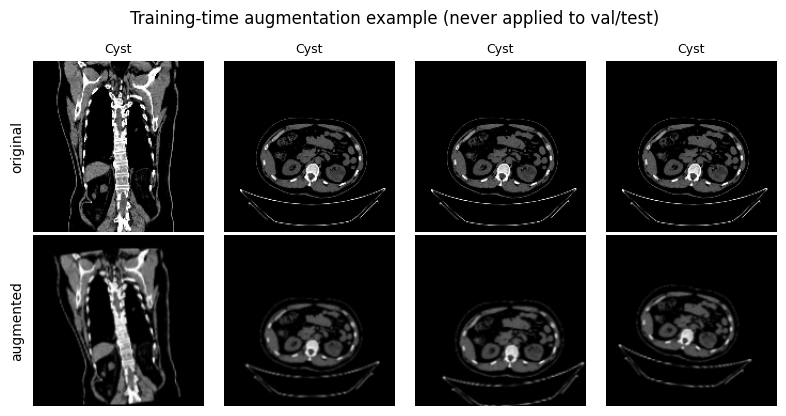

In [10]:
AUTOTUNE = tf.data.AUTOTUNE
def load_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bilinear")
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)

def make_ds(idx, training):
    paths, labels = df.path.values[idx], df.label.values[idx]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(lambda p, l: (load_img(p), l), num_parallel_calls=AUTOTUNE).cache()
    if training: ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, l: (tf.cast(x, tf.float32), l), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_idx, True), make_ds(val_idx, False), make_ds(test_idx, False)
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
print("tf.data pipelines ready. Training batches:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

# visual check of augmentation (training-only) on 4 training images
aug_demo = tf.keras.Sequential([tf.keras.layers.RandomRotation(0.03, fill_mode="constant"), tf.keras.layers.RandomZoom(0.1, fill_mode="constant"),
                                tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant")])
fig, axes = plt.subplots(2, 4, figsize=(8, 4.2))
for k, i in enumerate(train_idx[:4]):
    im = load_img(df.path[i]); axes[0, k].imshow(im.numpy()); axes[0, k].axis("off"); axes[0, k].set_title(df.class_name[i], fontsize=9)
    axes[1, k].imshow(aug_demo(tf.cast(im[None], tf.float32), training=True)[0].numpy().astype("uint8")); axes[1, k].axis("off")
axes[0, 0].text(-0.05, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.05, 0.5, "augmented", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Training-time augmentation example (never applied to val/test)"); plt.tight_layout()
plt.savefig(OUT_DIR / "PS21_augmentation_examples.png", dpi=150); plt.show()

## 12. Class-imbalance analysis and class weights
Stone is the smallest class. A model trained with plain cross-entropy can reach good accuracy while under-predicting Stone. **Class-weighted loss** multiplies each sample's loss by `n_samples / (n_classes × n_class_samples)`, so errors on rare classes cost more. Weights are computed from the **training labels only** (never from validation/test).

In [11]:
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.arange(4), y=y_train)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
print(pd.DataFrame({"class": CLASS_NAMES, "train_count": np.bincount(y_train, minlength=4), "weight": [round(CLASS_WEIGHTS[i], 3) for i in range(4)]}).to_string(index=False))

 class  train_count  weight
Normal         3985   0.605
  Cyst         2790   0.865
 Stone         1053   2.291
Tumour         1822   1.324


## 13. Model architecture and parameter summary
**MobileNetV2 (ImageNet weights) → Global Average Pooling → Dropout(0.3) → Dense(4, softmax).**
*Why:* transfer learning gives strong features from few epochs; MobileNetV2 is small (~2.3 M backbone parameters), so it trains within a free Colab session. Phase 1 trains only the head (backbone frozen); phase 2 gently fine-tunes the last 30 backbone layers at a 100× smaller learning rate.

In [12]:
from tensorflow.keras import layers, Model
WEIGHTS = None if DRY_RUN else "imagenet"
def build_model():
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=WEIGHTS)
    base.trainable = False
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="ct_slice")
    x = layers.RandomRotation(0.03, fill_mode="constant", seed=SEED)(inp)          # active only when training=True
    x = layers.RandomZoom(0.1, fill_mode="constant", seed=SEED)(x)
    x = layers.RandomTranslation(0.05, 0.05, fill_mode="constant", seed=SEED)(x)
    x = layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_rescale")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(DROPOUT, name="drop")(x)
    out = layers.Dense(4, activation="softmax", name="pred")(x)
    return Model(inp, out, name="kidney_mobilenetv2")

def param_counts(m):
    tr = int(sum(np.prod(w.shape) for w in m.trainable_weights)); tot = int(m.count_params())
    return dict(total=tot, trainable=tr, non_trainable=tot - tr)

m0 = build_model(); m0.summary(); print("Parameters (phase 1, backbone frozen):", param_counts(m0))
PARAMS_PHASE1 = param_counts(m0); del m0

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "kidney_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ct_slice (InputLayer)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 160, 160, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescale (Rescaling)   │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Parameters (phase 1, backbone frozen): {'total': 2263108, 'trainable': 5124, 'non_trainable': 2257984}


## 14. Model training
Two phases, both using **validation loss** for early stopping and checkpointing (the test set is never touched here):
1. **Head training** — backbone frozen, Adam, lr = 1e-3, ≤ 8 epochs.
2. **Fine-tuning** — last 30 backbone layers unfrozen (BatchNorm frozen), Adam, lr = 1e-5, ≤ 5 epochs.

The checkpoint with the lowest validation loss across both phases is selected. *Training duration* is the wall-clock time of the `fit` calls.

In [13]:
def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def run_training(tag, use_class_weights):
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(); log = {"tag": tag, "use_class_weights": use_class_weights}
    cw_arg = CLASS_WEIGHTS if use_class_weights else None
    ck1, ck2 = OUT_DIR / f"_{tag}_phase1.keras", OUT_DIR / f"_{tag}_phase2.keras"
    es = lambda: tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=ES_PATIENCE, restore_best_weights=True, verbose=1)
    # ---- phase 1
    compile_model(model, LR_HEAD); t = time.time()
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, class_weight=cw_arg, verbose=2,
                   callbacks=[es(), tf.keras.callbacks.ModelCheckpoint(ck1, monitor="val_loss", save_best_only=True)])
    d1 = time.time() - t
    # ---- phase 2
    base = [l for l in model.layers if isinstance(l, tf.keras.Model)][0]
    base.trainable = True
    for l in base.layers[:-FT_LAST_LAYERS]: l.trainable = False
    for l in base.layers:
        if isinstance(l, tf.keras.layers.BatchNormalization): l.trainable = False
    params_ft = param_counts(model)
    compile_model(model, LR_FINETUNE); t = time.time()
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, class_weight=cw_arg, verbose=2,
                   callbacks=[es(), tf.keras.callbacks.ModelCheckpoint(ck2, monitor="val_loss", save_best_only=True)])
    d2 = time.time() - t
    b1, b2 = min(h1.history["val_loss"]), min(h2.history["val_loss"])
    sel_phase = 2 if b2 < b1 else 1
    best = tf.keras.models.load_model(ck2 if sel_phase == 2 else ck1)
    keys = ["accuracy", "val_accuracy", "loss", "val_loss"]
    hist = {k: [float(v) for v in h1.history[k]] + [float(v) for v in h2.history[k]] for k in keys}
    log.update(history=hist, epochs_phase1=len(h1.history["loss"]), epochs_phase2=len(h2.history["loss"]),
               duration_phase1_s=d1, duration_phase2_s=d2, duration_total_s=d1 + d2, selected_phase=sel_phase,
               best_val_loss_phase1=float(b1), best_val_loss_phase2=float(b2), params_phase2=params_ft,
               best_epoch_global=int(np.argmin(h1.history["val_loss"])) if sel_phase == 1 else len(h1.history["loss"]) + int(np.argmin(h2.history["val_loss"])))
    print(f"[{tag}] phase1 epochs={log['epochs_phase1']} ({d1:.0f}s) | phase2 epochs={log['epochs_phase2']} ({d2:.0f}s) | selected phase {sel_phase}")
    return best, log

MODEL, TRAIN_LOG = run_training("weighted", use_class_weights=True)
MODEL.save(OUT_DIR / "PS21_kidney_classifier.keras")
print("Saved best model ->", OUT_DIR / "PS21_kidney_classifier.keras")
print(f"Total training duration (primary model): {TRAIN_LOG['duration_total_s']:.1f} s = {TRAIN_LOG['duration_total_s']/60:.1f} min")

Epoch 1/8
302/302 - 49s - 162ms/step - accuracy: 0.7794 - loss: 0.5972 - val_accuracy: 0.3588 - val_loss: 1.9616
Epoch 2/8
302/302 - 11s - 37ms/step - accuracy: 0.8444 - loss: 0.4484 - val_accuracy: 0.3797 - val_loss: 2.0550
Epoch 3/8
302/302 - 11s - 37ms/step - accuracy: 0.8626 - loss: 0.3991 - val_accuracy: 0.3553 - val_loss: 2.0826
Epoch 4/8
302/302 - 12s - 40ms/step - accuracy: 0.8803 - loss: 0.3474 - val_accuracy: 0.3483 - val_loss: 2.1018
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.
Epoch 1/5
302/302 - 22s - 73ms/step - accuracy: 0.8644 - loss: 0.3791 - val_accuracy: 0.3984 - val_loss: 1.8141
Epoch 2/5
302/302 - 14s - 45ms/step - accuracy: 0.9009 - loss: 0.2783 - val_accuracy: 0.4193 - val_loss: 1.6297
Epoch 3/5
302/302 - 14s - 46ms/step - accuracy: 0.9289 - loss: 0.2077 - val_accuracy: 0.4758 - val_loss: 1.3525
Epoch 4/5
302/302 - 13s - 43ms/step - accuracy: 0.9417 - loss: 0.1665 - val_accuracy: 0.4729 - val_loss: 1.4233
Epoch 5/5
302/302 - 

## 15. Training and validation learning curves

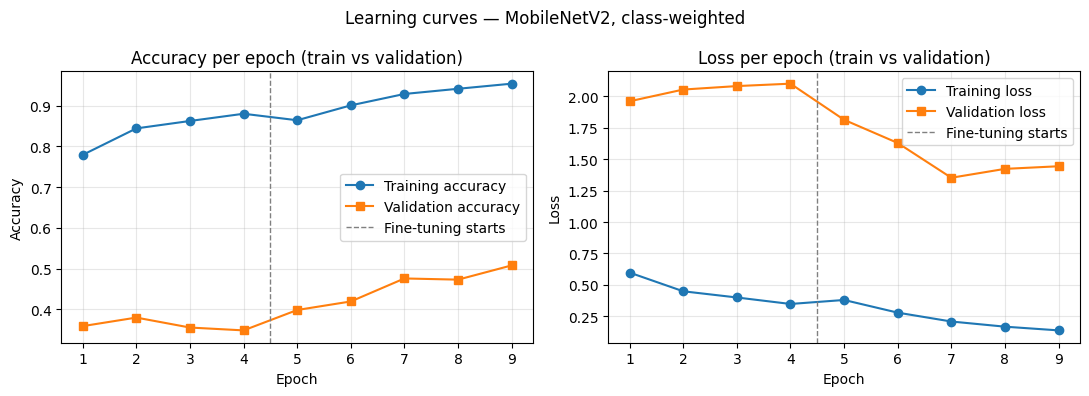

Selected checkpoint = epoch 7 | train acc 0.9289 | val acc 0.4758 | train loss 0.2077 | val loss 1.3525
Train-minus-validation accuracy gap at the selected epoch: +0.4531


In [14]:
H = TRAIN_LOG["history"]; ep = np.arange(1, len(H["loss"]) + 1); boundary = TRAIN_LOG["epochs_phase1"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, H["accuracy"], "o-", label="Training accuracy"); ax[0].plot(ep, H["val_accuracy"], "s-", label="Validation accuracy")
ax[1].plot(ep, H["loss"], "o-", label="Training loss"); ax[1].plot(ep, H["val_loss"], "s-", label="Validation loss")
for a, yl in zip(ax, ["Accuracy", "Loss"]):
    a.axvline(boundary + 0.5, color="grey", ls="--", lw=1, label="Fine-tuning starts"); a.set_xlabel("Epoch"); a.set_ylabel(yl); a.grid(alpha=.3); a.legend()
ax[0].set_title("Accuracy per epoch (train vs validation)"); ax[1].set_title("Loss per epoch (train vs validation)")
fig.suptitle("Learning curves — MobileNetV2, class-weighted"); plt.tight_layout()
plt.savefig(OUT_DIR / "PS21_learning_curves.png", dpi=200); plt.show()
bi = TRAIN_LOG["best_epoch_global"]
print(f"Selected checkpoint = epoch {bi+1} | train acc {H['accuracy'][bi]:.4f} | val acc {H['val_accuracy'][bi]:.4f} | train loss {H['loss'][bi]:.4f} | val loss {H['val_loss'][bi]:.4f}")
gap = H["accuracy"][bi] - H["val_accuracy"][bi]
print(f"Train-minus-validation accuracy gap at the selected epoch: {gap:+.4f}")

**How to read the curves (write your own sentence after the run).** Training accuracy far above validation accuracy, with validation loss rising, signals **over-fitting**. Both curves low and flat signal **under-fitting**. Curves that rise/fall together and flatten indicate **stable learning**. Note that dropout and augmentation are active during training, so training accuracy can legitimately be *below* validation accuracy. The grey dashed line marks where fine-tuning began.

## 16. Test-set predictions and metrics
**The test set is evaluated exactly once for the selected model** (chosen earlier using validation loss only). All numbers below come from the *same* `y_test` / `y_pred` arrays.

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
LABELS = [0, 1, 2, 3]
def evaluate_on_test(model):
    prob = model.predict(test_ds, verbose=0); pred = prob.argmax(1)       # test_ds is not shuffled -> same order as test_idx
    assert len(pred) == len(y_test)
    return dict(prob=prob, pred=pred,
                report=classification_report(y_test, pred, labels=LABELS, target_names=CLASS_NAMES, output_dict=True, zero_division=0),
                cm=confusion_matrix(y_test, pred, labels=LABELS),
                accuracy=float(accuracy_score(y_test, pred)),
                macro_f1=float(f1_score(y_test, pred, labels=LABELS, average="macro", zero_division=0)))

TEST = evaluate_on_test(MODEL)
rep = TEST["report"]
table = pd.DataFrame({c: {"precision": rep[c]["precision"], "recall": rep[c]["recall"], "f1-score": rep[c]["f1-score"], "support": int(rep[c]["support"])} for c in CLASS_NAMES}).T
table.loc["macro avg"] = [rep["macro avg"]["precision"], rep["macro avg"]["recall"], rep["macro avg"]["f1-score"], int(rep["macro avg"]["support"])]
table.to_csv(OUT_DIR / "PS21_classification_report.csv")
print(f"TEST SET (held-out, n = {len(y_test)})  [split: test]")
print(f"Test accuracy : {TEST['accuracy']:.2f}   (exact {TEST['accuracy']:.4f})")
print(f"Macro F1      : {TEST['macro_f1']:.2f}   (exact {TEST['macro_f1']:.4f})")
print(table.round(2).to_string())
STONE_RECALL = float(rep["Stone"]["recall"]); n_stone = int(rep["Stone"]["support"]); k_stone = int(TEST["cm"][2, 2])
print(f"\n>>> STONE RECALL = {STONE_RECALL:.2f}  ({k_stone} of {n_stone} Stone slices in the test set were found)  <<<")

TEST SET (held-out, n = 1079)  [split: test]
Test accuracy : 0.47   (exact 0.4708)
Macro F1      : 0.44   (exact 0.4395)
           precision  recall  f1-score  support
Normal          0.71    0.56      0.63    420.0
Cyst            0.98    0.29      0.45    400.0
Stone           0.34    0.50      0.41    204.0
Tumour          0.16    0.95      0.27     55.0
macro avg       0.55    0.58      0.44   1079.0

>>> STONE RECALL = 0.50  (102 of 204 Stone slices in the test set were found)  <<<


## 17. Confusion matrix
Rows = true class, columns = predicted class, fixed order `Normal, Cyst, Stone, Tumour`.

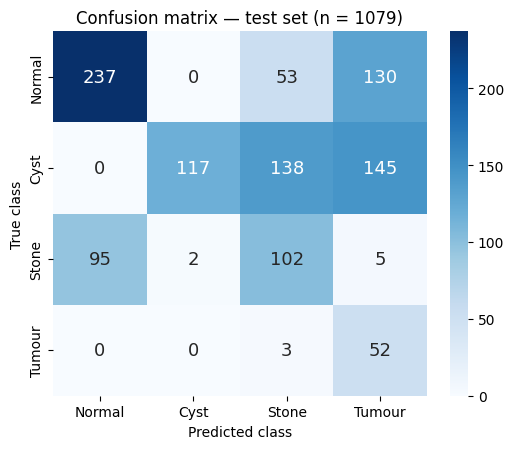

Caption: counts of test slices by true (rows) vs predicted (columns) class; diagonal = correct.
Largest confusions (true -> predicted : count): [('Cyst', 'Tumour', 145), ('Cyst', 'Stone', 138), ('Normal', 'Tumour', 130), ('Stone', 'Normal', 95), ('Normal', 'Stone', 53)]


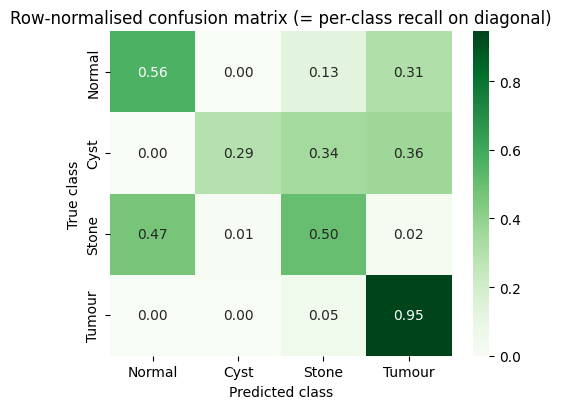

In [16]:
cm = TEST["cm"]
fig, ax = plt.subplots(figsize=(5.4, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=True, ax=ax, annot_kws={"size": 13})
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(f"Confusion matrix — test set (n = {cm.sum()})")
plt.tight_layout(); plt.savefig(OUT_DIR / "PS21_confusion_matrix.png", dpi=200); plt.show()
print("Caption: counts of test slices by true (rows) vs predicted (columns) class; diagonal = correct.")
off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(4) for j in range(4) if i != j and cm[i, j] > 0]
off.sort(key=lambda t: -t[2]); print("Largest confusions (true -> predicted : count):", off[:5] if off else "none - no errors")
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.2)); sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Row-normalised confusion matrix (= per-class recall on diagonal)")
plt.tight_layout(); plt.savefig(OUT_DIR / "PS21_confusion_matrix_normalised.png", dpi=150); plt.show()

## 18. Misclassified test images and error analysis
The images below are **real test errors**, shown from highest to lowest model confidence. *Confidence is the model's softmax probability for its predicted class — it is not clinical certainty.* If fewer than four errors exist, all are shown (nothing is fabricated).

Misclassified test images: 571 of 1079


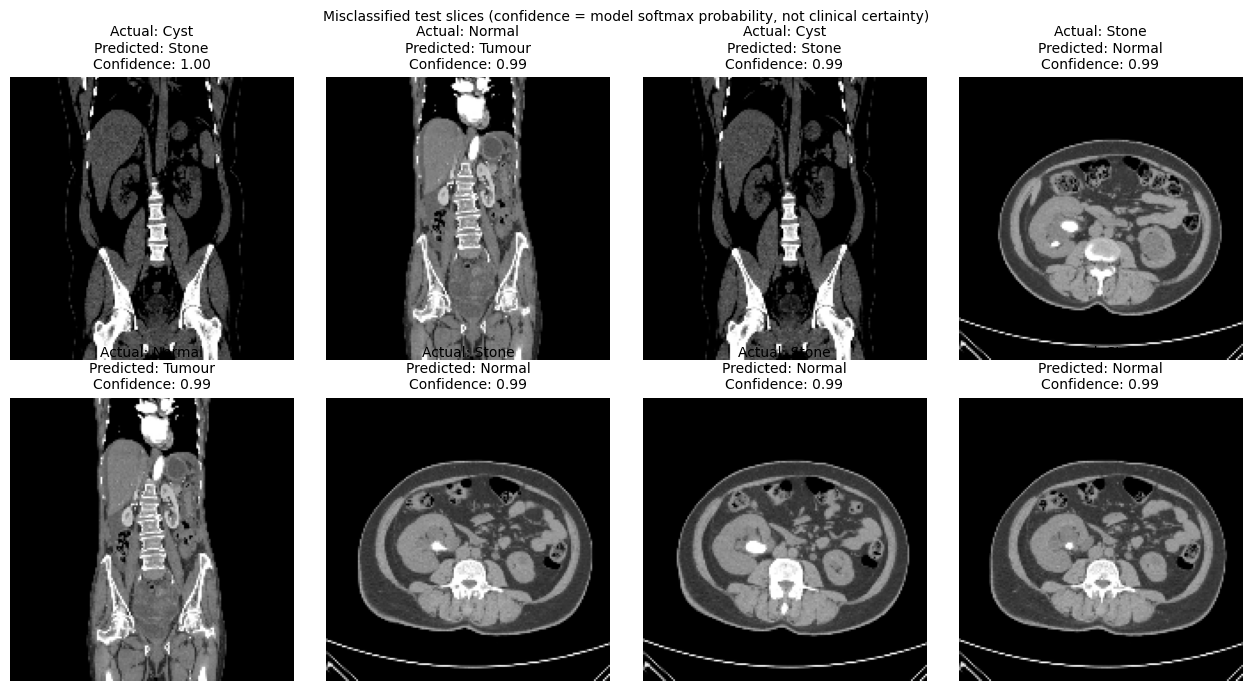

1. CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (3659).jpg: actual Cyst -> predicted Stone (confidence 1.00)
   Hypothesis (verify!): Small bright foci (calcification, contrast material, image noise) may resemble a stone.
2. CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Normal/Normal- (1374).jpg: actual Normal -> predicted Tumour (confidence 0.99)
   Hypothesis (verify!): Normal structures (renal pelvis, vessels, neighbouring bowel) can mimic a lesion on a single 2-D slice.
3. CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (3658).jpg: actual Cyst -> predicted Stone (confidence 0.99)
   Hypothesis (verify!): Small bright foci (calcification, contrast material, image noise) may resemble a stone.
4. CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Stone/Stone- (297).jpg: actual Stone -> predicted Normal (confidence 0.99)

In [17]:
pred, prob = TEST["pred"], TEST["prob"]
wrong = np.where(pred != y_test)[0]
wrong = wrong[np.argsort(-prob[wrong, pred[wrong]])]
print(f"Misclassified test images: {len(wrong)} of {len(y_test)}")
if len(wrong) < 4: print("NOTE: fewer than four errors occurred, so all", len(wrong), "are shown.")
show = wrong[:8]
ERRORS = [dict(image_path=df.rel_path[test_idx[i]], true=CLASS_NAMES[y_test[i]], pred=CLASS_NAMES[pred[i]], confidence=float(prob[i, pred[i]])) for i in show]
if len(show):
    cols = min(4, len(show)); rws = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(3.2 * cols, 3.5 * rws), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for k, i in enumerate(show):
        ax = axes[k // cols, k % cols]; ax.imshow(load_img(df.path[test_idx[i]]).numpy());
        ax.set_title(f"Actual: {CLASS_NAMES[y_test[i]]}\nPredicted: {CLASS_NAMES[pred[i]]}\nConfidence: {prob[i, pred[i]]:.2f}", fontsize=10)
    plt.suptitle("Misclassified test slices (confidence = model softmax probability, not clinical certainty)", fontsize=10); plt.tight_layout()
    plt.savefig(OUT_DIR / "PS21_misclassified_examples.png", dpi=170); plt.show()

def hypothesis(t, p):
    # Generic, clearly-labelled HYPOTHESES to verify by eye / Grad-CAM - not established causes.
    if t == "Stone": return "Stones are small, dense foci; after resizing to 160x160 they may span only a few pixels and be overlooked or look like normal tissue."
    if p == "Stone": return "Small bright foci (calcification, contrast material, image noise) may resemble a stone."
    if {t, p} == {"Cyst", "Tumour"}: return "Both are space-occupying lesions; on a single slice a dense/complex cyst and a low-contrast tumour can look similar."
    if t == "Normal": return "Normal structures (renal pelvis, vessels, neighbouring bowel) can mimic a lesion on a single 2-D slice."
    if p == "Normal": return "A small or low-contrast lesion can be close to normal parenchyma in a single slice."
    return "Appearance overlaps between these classes on a single slice."
for k, e in enumerate(ERRORS[:8], 1):
    print(f"{k}. {e['image_path']}: actual {e['true']} -> predicted {e['pred']} (confidence {e['confidence']:.2f})\n   Hypothesis (verify!): {hypothesis(e['true'], e['pred'])}")

### Grad-CAM (extra analysis): where was the model looking on its errors?
Grad-CAM highlights the image regions that most increased the **predicted** class score. It is a *qualitative* sanity check — it shows what the network used, not that the reasoning is clinically valid.

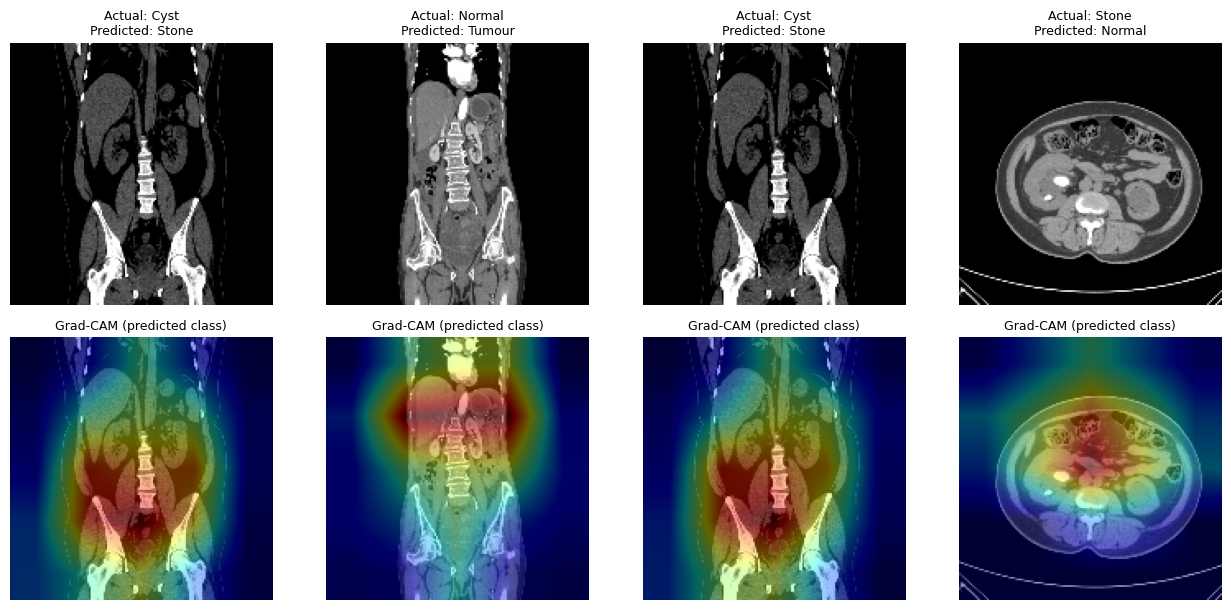

In [18]:
def gradcam(model, img_uint8, class_idx):
    base = [l for l in model.layers if isinstance(l, tf.keras.Model)][0]
    conv_model = tf.keras.Model(base.input, base.get_layer("out_relu").output)
    x = tf.convert_to_tensor(img_uint8[None].astype("float32") / 127.5 - 1.0)
    conv = conv_model(x, training=False)
    with tf.GradientTape() as tape:
        tape.watch(conv)
        score = model.get_layer("pred")(model.get_layer("gap")(conv))[:, class_idx]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2)); cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return np.asarray(Image.fromarray((cam * 255).astype("uint8")).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0

gshow = wrong[:4]
if len(gshow):
    fig, axes = plt.subplots(2, len(gshow), figsize=(3.2 * len(gshow), 6.2), squeeze=False)
    for k, i in enumerate(gshow):
        im = load_img(df.path[test_idx[i]]).numpy(); hm = gradcam(MODEL, im, int(pred[i]))
        axes[0, k].imshow(im); axes[0, k].set_title(f"Actual: {CLASS_NAMES[y_test[i]]}\nPredicted: {CLASS_NAMES[pred[i]]}", fontsize=9); axes[0, k].axis("off")
        axes[1, k].imshow(im); axes[1, k].imshow(hm, cmap="jet", alpha=0.4); axes[1, k].set_title("Grad-CAM (predicted class)", fontsize=9); axes[1, k].axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / "PS21_gradcam_errors.png", dpi=150); plt.show()
else: print("No errors to explain with Grad-CAM.")

### Your own error analysis (write this after looking at the images above)
The rubric asks for *"the likely reason for each error"*. The hypotheses printed above are generic starting points. **Look at each image and Grad-CAM, then write one honest sentence per error in the list below** (re-run the report cell afterwards so it appears in the PDF). Do not claim an anatomical cause you cannot see.

In [19]:
# Fill after inspecting the images. One short sentence per misclassified image (same order as printed above). Leave [] if you have not yet.
ERROR_NOTES = [
    # "1: ...",
    # "2: ...",
]
print(f"{len(ERROR_NOTES)} student notes recorded.")

0 student notes recorded.


## 19. Justified extra analysis: class-weighted vs unweighted training
**Question:** does class weighting improve **Stone recall** and macro-F1 on the same split? The primary model (class-weighted) was fixed *before* looking at this comparison, and the unweighted baseline uses the identical split, schedule and seed. No hyper-parameters are tuned on the test set.

Epoch 1/8
302/302 - 18s - 61ms/step - accuracy: 0.7877 - loss: 0.5749 - val_accuracy: 0.3634 - val_loss: 1.6287
Epoch 2/8
302/302 - 12s - 39ms/step - accuracy: 0.8647 - loss: 0.4131 - val_accuracy: 0.4287 - val_loss: 1.5350
Epoch 3/8
302/302 - 12s - 38ms/step - accuracy: 0.8869 - loss: 0.3181 - val_accuracy: 0.4170 - val_loss: 1.5608
Epoch 4/8
302/302 - 14s - 47ms/step - accuracy: 0.8961 - loss: 0.3052 - val_accuracy: 0.4240 - val_loss: 1.4573
Epoch 5/8
302/302 - 12s - 39ms/step - accuracy: 0.9117 - loss: 0.2575 - val_accuracy: 0.4653 - val_loss: 1.3465
Epoch 6/8
302/302 - 11s - 38ms/step - accuracy: 0.9095 - loss: 0.2643 - val_accuracy: 0.3902 - val_loss: 1.7694
Epoch 7/8
302/302 - 11s - 37ms/step - accuracy: 0.9169 - loss: 0.2448 - val_accuracy: 0.4857 - val_loss: 1.3711
Epoch 8/8
302/302 - 12s - 41ms/step - accuracy: 0.9215 - loss: 0.2270 - val_accuracy: 0.5265 - val_loss: 1.3121
Restoring model weights from the end of the best epoch: 8.
Epoch 1/5
302/302 - 21s - 69ms/step - accurac

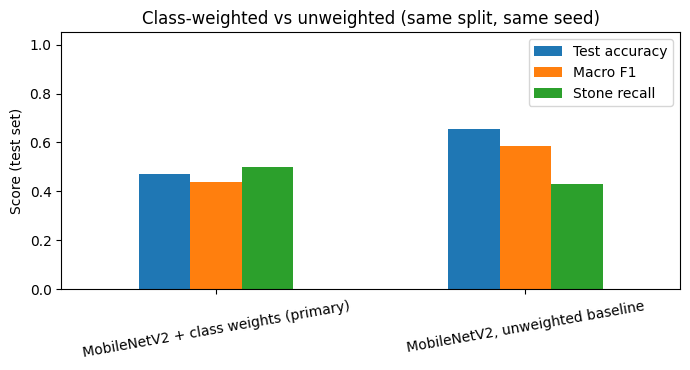

In [20]:
COMPARISON = None
if RUN_COMPARISON:
    MODEL_UW, LOG_UW = run_training("unweighted", use_class_weights=False)
    TEST_UW = evaluate_on_test(MODEL_UW)
    COMPARISON = {}
    for name, T_, L_ in [("MobileNetV2 + class weights (primary)", TEST, TRAIN_LOG), ("MobileNetV2, unweighted baseline", TEST_UW, LOG_UW)]:
        r_ = T_["report"]
        COMPARISON[name] = dict(accuracy=T_["accuracy"], macro_f1=T_["macro_f1"], stone_recall=r_["Stone"]["recall"], duration_total_s=L_["duration_total_s"],
                                per_class={c: dict(precision=r_[c]["precision"], recall=r_[c]["recall"], f1=r_[c]["f1-score"]) for c in CLASS_NAMES},
                                confusion_matrix=T_["cm"].tolist(), epochs_phase1=L_["epochs_phase1"], epochs_phase2=L_["epochs_phase2"])
    cdf = pd.DataFrame({k: {"Test accuracy": v["accuracy"], "Macro F1": v["macro_f1"], "Stone recall": v["stone_recall"],
                            **{f"Recall {c}": v["per_class"][c]["recall"] for c in CLASS_NAMES}} for k, v in COMPARISON.items()}).T
    print(cdf.round(2).to_string())
    d_ = COMPARISON["MobileNetV2 + class weights (primary)"]["stone_recall"] - COMPARISON["MobileNetV2, unweighted baseline"]["stone_recall"]
    print(f"\nStone recall change due to class weighting: {d_:+.2f} (on {n_stone} Stone test slices, so one slice = {1/max(n_stone,1):.3f}).")
    print("Caution: with a small Stone test set and a single seed, differences of a few slices are within run-to-run noise. Treat this as indicative, not conclusive.")
    ax = cdf[["Test accuracy", "Macro F1", "Stone recall"]].plot(kind="bar", figsize=(7, 3.8), rot=10); ax.set_ylabel("Score (test set)"); ax.set_title("Class-weighted vs unweighted (same split, same seed)")
    ax.set_ylim(0, 1.05); plt.tight_layout(); plt.savefig(OUT_DIR / "PS21_weighting_comparison.png", dpi=170); plt.show()
else: print("RUN_COMPARISON=False: comparison skipped (described as future work in the report).")

## 20. Limitations, ethics and clinical safety
* **Not a diagnostic device.** This is a classroom experiment; it has had no clinical validation, regulatory review or prospective testing. It must never be used on its own to diagnose or exclude disease.
* **Possible data leakage.** Patient/study IDs are not available in the public files, so a true patient-level split was **not** possible. The near-duplicate-grouped split removes detectable duplicates only (Section 10); same-patient similarity may remain, so test scores can be optimistic.
* **Dataset bias and provenance.** Images come from one public source with unknown scanners, protocols, and patient demographics; performance on other hospitals, devices or populations is unknown (domain shift).
* **Class imbalance & small Stone test set.** Stone recall is estimated from few examples and has a wide uncertainty interval.
* **2-D slices, no context.** Radiologists read 3-D studies with clinical history; a single JPEG slice is a much weaker input.
* **Privacy.** Medical images can be sensitive. Only public, de-identified data is used; any real-world use needs consent, de-identification checks and secure handling.
* **Human in the loop.** Wrong predictions have real cost: a missed stone or tumour (false negative) can delay treatment; false alarms cause anxiety and unnecessary tests. Predictions must be reviewed by a qualified clinician.

## 21. Final results summary and results file
The next cell gathers every measured value into `PS21_results.json`. The report is generated from this file only.

In [21]:
R = dict(
    student=STUDENT, github_url=GITHUB_URL, dry_run=DRY_RUN, date=datetime.date.today().isoformat(), class_names=CLASS_NAMES, versions=VERSIONS,
    gpu=[g.name for g in GPUS] if GPUS else None,
    dataset=dict(source="CT Kidney Dataset, Kaggle (nazmul0087)", url="https://www.kaggle.com/datasets/" + KAGGLE_SLUG,
                 n_total=int(N_TOTAL), class_counts={c: int(counts[c]) for c in CLASS_NAMES}, n_unreadable_excluded=N_UNREADABLE,
                 assignment_quoted_n=12446, patient_ids_available=bool(PATIENT_IDS_AVAILABLE or GROUP_REGEX)),
    split=dict(method=SPLIT_METHOD, seed=SEED, sizes=SPLIT_SIZES, class_counts=SPLIT_COUNTS, leakage=LEAKAGE),
    config=dict(architecture="MobileNetV2 (ImageNet) + GAP + Dropout + Dense(4, softmax)", weights=("imagenet" if WEIGHTS else "none (smoke test)"),
                img_size=IMG_SIZE, batch_size=BATCH_SIZE, optimizer="Adam", lr_head=LR_HEAD, lr_finetune=LR_FINETUNE, loss="sparse categorical cross-entropy",
                class_weights={CLASS_NAMES[i]: round(CLASS_WEIGHTS[i], 4) for i in range(4)}, dropout=DROPOUT, max_epochs_head=EPOCHS_HEAD, max_epochs_finetune=EPOCHS_FT,
                finetune_last_layers=FT_LAST_LAYERS, early_stopping=f"monitor val_loss, patience {ES_PATIENCE}, restore best weights",
                augmentation="rotation +-~11 deg, zoom +-10%, shift +-5% (training only, no flips)", normalisation="rescale to [-1, 1]"),
    training=dict(epochs_phase1=TRAIN_LOG["epochs_phase1"], epochs_phase2=TRAIN_LOG["epochs_phase2"], selected_phase=TRAIN_LOG["selected_phase"],
                  duration_total_s=TRAIN_LOG["duration_total_s"], duration_phase1_s=TRAIN_LOG["duration_phase1_s"], duration_phase2_s=TRAIN_LOG["duration_phase2_s"],
                  best_epoch_global=TRAIN_LOG["best_epoch_global"], history=TRAIN_LOG["history"], params_phase1=PARAMS_PHASE1, params_phase2=TRAIN_LOG["params_phase2"]),
    test=dict(n=int(len(y_test)), accuracy=TEST["accuracy"], macro_f1=TEST["macro_f1"], stone_recall=STONE_RECALL,
              per_class={c: dict(precision=rep[c]["precision"], recall=rep[c]["recall"], f1=rep[c]["f1-score"], support=int(rep[c]["support"])) for c in CLASS_NAMES},
              confusion_matrix=TEST["cm"].tolist(), n_errors=int(len(wrong))),
    comparison=COMPARISON, errors=ERRORS, error_notes=ERROR_NOTES)
with open(OUT_DIR / "PS21_results.json", "w") as f: json.dump(R, f, indent=2, default=float)
print("Saved", OUT_DIR / "PS21_results.json")
print("="*70, "\nFINAL SUMMARY (these exact values feed the report)\n" + "="*70)
print(f"Dataset: {N_TOTAL} usable images | counts {R['dataset']['class_counts']} | unreadable excluded: {N_UNREADABLE}")
print(f"Split: {SPLIT_METHOD} | seed {SEED} | sizes {SPLIT_SIZES}")
print(f"Epochs completed: phase 1 = {R['training']['epochs_phase1']}, phase 2 = {R['training']['epochs_phase2']} | training time = {R['training']['duration_total_s']:.1f} s")
print(f"TEST (n={R['test']['n']}): accuracy {TEST['accuracy']:.2f} | macro-F1 {TEST['macro_f1']:.2f} | STONE RECALL {STONE_RECALL:.2f}")
print(table.round(2).to_string()); print("Confusion matrix (rows true, cols predicted; order", CLASS_NAMES, "):\n", TEST["cm"])

Saved /content/PS21_outputs/PS21_results.json
FINAL SUMMARY (these exact values feed the report)
Dataset: 12446 usable images | counts {'Normal': 5077, 'Cyst': 3709, 'Stone': 1377, 'Tumour': 2283} | unreadable excluded: 0
Split: near-duplicate-grouped, stratified (proxy; NOT patient-level) | seed 42 | sizes {'train': 9650, 'val': 1717, 'test': 1079}
Epochs completed: phase 1 = 4, phase 2 = 5 | training time = 158.8 s
TEST (n=1079): accuracy 0.47 | macro-F1 0.44 | STONE RECALL 0.50
           precision  recall  f1-score  support
Normal          0.71    0.56      0.63    420.0
Cyst            0.98    0.29      0.45    400.0
Stone           0.34    0.50      0.41    204.0
Tumour          0.16    0.95      0.27     55.0
macro avg       0.55    0.58      0.44   1079.0
Confusion matrix (rows true, cols predicted; order ['Normal', 'Cyst', 'Stone', 'Tumour'] ):
 [[237   0  53 130]
 [  0 117 138 145]
 [ 95   2 102   5]
 [  0   0   3  52]]


## 22. Model saving
The best checkpoint was already saved in Section 14 as `PS21_kidney_classifier.keras`. The cell lists every artifact produced.

In [22]:
for p in sorted(OUT_DIR.glob("*")):
    if not p.name.startswith("_"): print(f"{p.name:<45s} {p.stat().st_size/1024:9.1f} KB")
for p in OUT_DIR.glob("_*.keras"): p.unlink()     # remove intermediate phase checkpoints

PS21_augmentation_examples.png                    253.2 KB
PS21_class_distribution.png                        55.6 KB
PS21_classification_report.csv                      0.3 KB
PS21_confusion_matrix.png                          65.7 KB
PS21_confusion_matrix_normalised.png               52.9 KB
PS21_gradcam_errors.png                           859.6 KB
PS21_kidney_classifier.keras                    21269.1 KB
PS21_learning_curves.png                          136.5 KB
PS21_misclassified_examples.png                   263.2 KB
PS21_results.json                                   9.6 KB
PS21_sample_images.png                            787.1 KB
PS21_split_manifest.csv                          1524.5 KB
PS21_weighting_comparison.png                      74.0 KB


## 23. Reproducibility and export instructions
1. **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**.
2. Seeds are fixed (`SEED = 42`, used for Python, NumPy, TensorFlow and the data split). The exact split is saved in `PS21_split_manifest.csv`; library versions are printed in Section 3 and stored in `PS21_results.json`. GPU kernels can still cause tiny run-to-run differences, so re-running may change numbers in the last decimal place.
3. Every metric in the report is read from `PS21_results.json`, which is written by Section 21.
4. After running, download the zip created by the last cell, commit the notebook **with outputs** (File → Save a copy in GitHub) and paste the repository link into `GITHUB_URL` (Section 3), then re-run only the report cell (Section 26).

## 24. References and AI-assistance declaration
1. M. N. Islam, M. Hasan, M. K. Hossain, M. G. R. Alam, M. Z. Uddin, A. Soylu, "Vision transformer and explainable transfer learning models for auto detection of kidney cyst, stone and tumor from CT-radiography," *Scientific Reports* 12, 11440 (2022), doi:10.1038/s41598-022-15634-4. Dataset: CT Kidney Dataset, Kaggle, https://www.kaggle.com/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone *(verify the citation requested on the dataset page)*.
2. M. Sandler, A. Howard, M. Zhu, A. Zhmoginov, L.-C. Chen, "MobileNetV2: Inverted Residuals and Linear Bottlenecks," *CVPR* 2018.
3. R. R. Selvaraju et al., "Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization," *ICCV* 2017.

**Literature context (published benchmark — NOT a result of this experiment).** The dataset paper [1] describes the creation of this 12,446-image dataset and reports that a Swin Transformer reached 99.30 % accuracy among six models it compared. Its abstract does not describe a patient-level split, so such figures should not be treated as a target for this assignment; with a different split, backbone, image size and training budget, results here can legitimately differ. Compare your numbers with it only as context, and read the paper's methods section to see how its data were split.

**AI-assistance declaration.** An AI assistant (Claude, by Anthropic) was used to help structure and draft the code and the report text of this submission. The experiment itself (training, evaluation, all numbers and figures) is produced by running this notebook; the student has reviewed the code and is responsible for explaining it. *Published benchmark scores from the literature are not reproduced as results of this experiment.*

# Part 2 — Report generation (reads `PS21_results.json` only)
Run these cells after Section 21. They build the two-page PDF and the Word report from the saved results file, then validate them.

## 25. Build report figures and content from `PS21_results.json`

In [28]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.enums import TA_JUSTIFY, TA_CENTER
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage
from reportlab.lib import colors

R = json.load(open(OUT_DIR / "PS21_results.json"))          # the single source of truth for the report
f2 = lambda v: f"{v:.2f}"
CN = R["class_names"]; D, S, C, T, TE = R["dataset"], R["split"], R["config"], R["training"], R["test"]
CMX = np.array(TE["confusion_matrix"])
assert CN == ["Normal", "Cyst", "Stone", "Tumour"], "class order changed"
assert CMX.sum() == TE["n"] == sum(S["sizes"].values()) - S["sizes"]["train"] - S["sizes"]["val"], "confusion matrix / test size mismatch"
assert sum(S["sizes"].values()) == D["n_total"] == sum(D["class_counts"].values()), "split sizes / class counts do not add up"

def make_report_figs(R):
    H = R["training"]["history"]; ep = np.arange(1, len(H["loss"]) + 1); b = R["training"]["epochs_phase1"] + 0.5
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(4.1, 3.5), sharex=True)
    a1.plot(ep, H["accuracy"], "o-", ms=3, label="Train acc."); a1.plot(ep, H["val_accuracy"], "s-", ms=3, label="Val. acc."); a1.set_ylabel("Accuracy", fontsize=8)
    a2.plot(ep, H["loss"], "o-", ms=3, label="Train loss"); a2.plot(ep, H["val_loss"], "s-", ms=3, label="Val. loss"); a2.set_ylabel("Loss", fontsize=8); a2.set_xlabel("Epoch", fontsize=8)
    for a in (a1, a2):
        a.axvline(b, color="grey", ls="--", lw=0.8); a.grid(alpha=.3); a.legend(fontsize=6.5, loc="best"); a.tick_params(labelsize=7)
    a1.set_title("Learning curves (dashed: fine-tuning starts)", fontsize=8); fig.tight_layout(); fig.savefig(OUT_DIR / "_report_curves.png", dpi=250); plt.close(fig)
    fig, ax = plt.subplots(figsize=(2.85, 2.75))
    sns.heatmap(CMX, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CN, yticklabels=CN, ax=ax, annot_kws={"size": 9})
    ax.set_xlabel("Predicted", fontsize=8); ax.set_ylabel("True", fontsize=8); ax.tick_params(labelsize=7); ax.set_title(f"Test confusion matrix (n={TE['n']})", fontsize=8)
    fig.tight_layout(); fig.savefig(OUT_DIR / "_report_cm.png", dpi=250); plt.close(fig)
make_report_figs(R)

def date_str(): return datetime.date.today().strftime("%d %B %Y")

def build_content(R):
    pc = TE["per_class"]; sz = S["sizes"]; L = S["leakage"]; errs = R["errors"]; ncls = D["class_counts"]
    pct = lambda k: round(100 * sz[k] / D["n_total"])
    link = R["github_url"] if R["github_url"] else "[to be added after publishing the notebook to GitHub]"
    blocks = []
    if R["dry_run"]: blocks.append(("warn", "SMOKE TEST ONLY - THE NUMBERS BELOW ARE NOT REAL EXPERIMENTAL RESULTS"))
    blocks.append(("hdr", [f"<b>{STUDENT['name']}.</b> {STUDENT['reg']}. {STUDENT['section']}.", f"<b>{STUDENT['ps']} - {STUDENT['title']}</b>", f"Date: {date_str()}. Notebook: {link}"]))
    # 1
    blocks += [("h", "1. Problem and Objective"),
      ("p", "The task is to classify a single kidney CT slice as Normal, Cyst, Stone or Tumour, a triage-support problem where different mistakes have different costs. "
            "Success is judged on the held-out test set by macro-F1 (all four classes weighted equally) and by Stone recall (the smallest class and a costly miss), "
            "reported with accuracy, per-class precision/recall/F1 and the confusion matrix.")]
    # 2
    leak_txt = ("Patient/study IDs could not be recovered from the public files, so a patient-level split was not possible; images were grouped by near-duplicate "
                f"perceptual hash (distance <= {L['threshold_bits']} of 256 bits, {L['n_groups']} groups) and groups were kept in one partition (stratified, seed {S['seed']})."
                if L["threshold_bits"] is not None else f"Images were grouped by the patient/study ID parsed from file names and each group kept in one partition (seed {S['seed']}).")
    cw = C["class_weights"]
    blocks += [("h", "2. Dataset and Preprocessing"),
      ("p", f"Source: CT Kidney Dataset (Kaggle) [1]; {D['n_total']} readable images were used ({D['n_unreadable_excluded']} unreadable excluded): "
            f"Normal {ncls['Normal']}, Cyst {ncls['Cyst']}, Stone {ncls['Stone']}, Tumour {ncls['Tumour']} (folder 'Tumor' mapped to Tumour). "
            f"Split 80/10/10 into train/validation/test = {sz['train']}/{sz['val']}/{sz['test']} images. {leak_txt} "
            f"Images were decoded to 3 channels, resized to {C['img_size']}x{C['img_size']} and rescaled to [-1, 1]. Augmentation (training only, no flips): {C['augmentation']}. "
            f"Imbalance was handled with class-weighted loss computed from training labels only (Normal {cw['Normal']:.2f}, Cyst {cw['Cyst']:.2f}, Stone {cw['Stone']:.2f}, Tumour {cw['Tumour']:.2f}).")]
    # 3
    p1, p2 = T["params_phase1"], T["params_phase2"]
    hp = [["Architecture", "MobileNetV2 + GAP + Dropout + Dense(4)"], ["Weights", C["weights"]], ["Input size", f"{C['img_size']}x{C['img_size']}x3"], ["Batch size", str(C["batch_size"])],
          ["Optimiser", C["optimizer"]], ["LR head / fine-tune", f"{C['lr_head']:g} / {C['lr_finetune']:g}"], ["Loss", "Weighted sparse CE"], ["Dropout", f"{C['dropout']}"],
          ["Epochs run (P1 / P2)", f"{T['epochs_phase1']} / {T['epochs_phase2']}"], ["Max epochs (P1 / P2)", f"{C['max_epochs_head']} / {C['max_epochs_finetune']}"],
          ["Early stopping", f"val-loss, patience {C['early_stopping'].split('patience ')[1].split(',')[0]}"], ["Split seed", str(S["seed"])]]
    hp_rows = [hp[i] + hp[i + 6] for i in range(6)]
    blocks += [("h", "3. Methodology"),
      ("p", f"An ImageNet-pretrained MobileNetV2 backbone feeds global average pooling, dropout and a 4-way softmax. Phase 1 (P1) trains only the head with the backbone frozen ({p1['trainable']:,} of {p1['total']:,} parameters trainable); "
            f"phase 2 (P2) fine-tunes the last {C['finetune_last_layers']} backbone layers with BatchNorm frozen ({p2['trainable']:,} trainable) at a 100x smaller learning rate. "
            f"Training used Adam and early stopping on validation loss with best weights restored; the checkpoint with the lowest validation loss (phase {T['selected_phase']}) was selected, "
            "so the test set was never used for tuning or model selection."),
      ("table", "Table 1. Hyperparameters actually used.", [["Setting", "Value", "Setting", "Value"]] + hp_rows, [3.3, 5.2, 3.3, 5.2], 8.5)]
    # 4
    def cell(c, d): return f"{f2(d[c]['precision'])}/{f2(d[c]['recall'])}/{f2(d[c]['f1'])}"
    rows = [["Model", "Acc.", "Macro-F1"] + [f"{c} P/R/F1" for c in CN] + ["Stone rec.", "Train time"]]
    rows.append(["MobileNetV2, class-weighted", f2(TE["accuracy"]), f2(TE["macro_f1"])] + [cell(c, pc) for c in CN] + [f2(TE["stone_recall"]), f"{T['duration_total_s']:.0f} s"])
    if R["comparison"]:
        u = R["comparison"]["MobileNetV2, unweighted baseline"]
        rows.append(["MobileNetV2, unweighted", f2(u["accuracy"]), f2(u["macro_f1"])] + [cell(c, u["per_class"]) for c in CN] + [f2(u["stone_recall"]), f"{u['duration_total_s']:.0f} s"])
    blocks += [("h", "4. Results"),
      ("p", f"All numbers are from the held-out test split (n = {TE['n']}; {', '.join(f'{c} {pc[c]['support']}' for c in CN)}). Test accuracy {f2(TE['accuracy'])}, macro-F1 {f2(TE['macro_f1'])}, "
            f"<b>Stone recall {f2(TE['stone_recall'])}</b> ({CMX[2,2]} of {pc['Stone']['support']} Stone slices found). Total training time: {T['duration_total_s']:.0f} s (wall-clock of the fit calls)."),
      ("table", "Table 2. Test-set results (P/R/F1 = precision/recall/F1; second row is the extra class-weighting analysis).", rows, [3.1, 1.0, 1.35, 2.15, 2.15, 2.15, 2.15, 1.2, 1.2], 7.5),
      ("figs", "Fig. 1. Training/validation accuracy and loss per epoch.", "Fig. 2. Confusion matrix on the test set.")]
    # 5
    off = sorted([(CN[i], CN[j], int(CMX[i, j])) for i in range(4) for j in range(4) if i != j and CMX[i, j] > 0], key=lambda t: -t[2])
    conf = ("The test set has no misclassified slices." if not off else "Largest confusions (true to predicted): " + "; ".join(f"{a} to {b} ({n})" for a, b, n in off[:3]) + ".")
    ne = TE["n_errors"]; top = errs[:4]
    ex = ("; ".join(f"{e['true']} to {e['pred']} (confidence {f2(e['confidence'])})" for e in top) if top else "none")
    bi = T["best_epoch_global"]; H = T["history"]; gap = H["accuracy"][bi] - H["val_accuracy"][bi]
    if gap > 0.05: fit = f"Training accuracy exceeded validation accuracy by {gap:.2f} at the selected epoch, indicating some over-fitting."
    elif H["val_accuracy"][bi] < 0.80: fit = f"Validation accuracy at the selected epoch was only {f2(H['val_accuracy'][bi])}, suggesting under-fitting."
    else: fit = f"Training and validation accuracy at the selected epoch were {f2(H['accuracy'][bi])} and {f2(H['val_accuracy'][bi])} (gap {gap:+.2f}), so learning appeared stable without marked over-fitting."
    cmp_txt = ""
    if R["comparison"]:
        u = R["comparison"]["MobileNetV2, unweighted baseline"]; d = TE["stone_recall"] - u["stone_recall"]
        cmp_txt = (f" Without class weights Stone recall was {f2(u['stone_recall'])} (macro-F1 {f2(u['macro_f1'])}); weighting changed Stone recall by {d:+.2f}, "
                   f"but with only {pc['Stone']['support']} Stone test slices and one seed this is indicative, not conclusive.")
    leak_a = (f"A plain stratified random split would have left {L['naive_random_split_test_with_train_neighbour']} of {L['n_test_checked']} test images "
              f"({L['naive_random_split_pct']:.1f}%) with a near-duplicate in training, versus {L['grouped_split_test_with_train_neighbour']} with the grouped split, "
              "which is how random splitting inflates accuracy. " if L["threshold_bits"] is not None else "")
    leak_b = ("This proxy cannot detect same-patient slices that look different, so scores may remain optimistic; the split is not patient-level." if L["threshold_bits"] is not None
              else "Splitting by patient/study ID prevents same-patient slices from crossing partitions.")
    notes = (" Student notes: " + " ".join(R["error_notes"][:4])) if R.get("error_notes") else " Images, Grad-CAM maps and the discussion of each error are in notebook Section 18."
    blocks += [("h", "5. Analysis and Discussion"),
      ("p", f"{conf} {ne} of {TE['n']} test slices were misclassified; the highest-confidence errors were {ex}.{notes} {fit} "
            f"Stone recall was {f2(TE['stone_recall'])}.{cmp_txt} <b>Leakage:</b> {leak_a}{leak_b}")]
    # 6, 7
    blocks += [("h", "6. Real-world Relevance, Limitations and Ethics"),
      ("p", "Such a model could assist research on triage or second-reading support for kidney CT. It is not clinically validated and must not be used as a stand-alone diagnostic tool: it sees single 2-D slices without clinical context, "
            "the data come from one public source with unknown scanners and demographics (dataset bias and domain shift), Stone has few test examples, patient-level leakage cannot be excluded, "
            "and false negatives (a missed stone or tumour) carry real harm. Only public, de-identified images were used; any real deployment needs consent, privacy safeguards and clinician review."),
      ("h", "7. Conclusion and Future Work"),
      ("p", f"On the held-out test set the MobileNetV2 model reached accuracy {f2(TE['accuracy'])}, macro-F1 {f2(TE['macro_f1'])} and Stone recall {f2(TE['stone_recall'])}. "
            "Next, I would obtain patient/study identifiers for a true patient-level split and test on an external hospital dataset to measure real generalisation."),
      ("refs", "References: [1] M. N. Islam et al., Vision transformer and explainable transfer learning models for auto detection of kidney cyst, stone and tumor from CT-radiography, Sci. Rep. 12, 11440 (2022), doi:10.1038/s41598-022-15634-4; "
               "CT Kidney Dataset, Kaggle (nazmul0087). [2] M. Sandler et al., MobileNetV2, CVPR 2018. "
               "<i>AI-assistance declaration:</i> an AI assistant (Claude, Anthropic) helped draft the code and report text; all results come from the notebook run and were reviewed by the author.")]
    return blocks
BLOCKS = build_content(R); print("Report content built from PS21_results.json:", len(BLOCKS), "blocks")

Report content built from PS21_results.json: 19 blocks


## 26. Create the PDF (≤ 2 pages) and the Word report

In [29]:
from pypdf import PdfReader
PDF_PATH = OUT_DIR / "RA2311026050010_PS21_Report.pdf"; DOCX_PATH = OUT_DIR / "RA2311026050010_PS21_Report.docx"
BODY = ParagraphStyle("b", fontName="Times-Roman", fontSize=11, leading=12.6, alignment=TA_JUSTIFY, spaceAfter=2)
HEAD = ParagraphStyle("h", fontName="Times-Bold", fontSize=12, leading=13.8, spaceBefore=4, spaceAfter=1)
CAP = ParagraphStyle("c", fontName="Times-Italic", fontSize=9, leading=10.2, alignment=TA_CENTER, spaceAfter=2)
HDR = ParagraphStyle("hd", parent=BODY, alignment=0, spaceAfter=0)
WARN = ParagraphStyle("w", parent=BODY, textColor=colors.red, fontName="Times-Bold", alignment=TA_CENTER)
REFS = ParagraphStyle("r", parent=BODY, fontSize=9.5, leading=10.8)

def build_pdf(blocks, path, fig_scale=1.0):
    doc = SimpleDocTemplate(str(path), pagesize=A4, leftMargin=2*cm, rightMargin=2*cm, topMargin=2*cm, bottomMargin=2*cm,
                            title=f"{STUDENT['reg']}_PS21_Report", author=STUDENT["name"])
    W = 17 * cm; st = []
    def img(p, w_cm):
        iw, ih = PIL.Image.open(p).size; return RLImage(str(p), width=w_cm * cm, height=w_cm * cm * ih / iw)
    for b in blocks:
        k = b[0]
        if k == "warn": st.append(Paragraph(b[1], WARN))
        elif k == "hdr": st += [Paragraph(t, HDR) for t in b[1]]
        elif k == "h": st.append(Paragraph(b[1], HEAD))
        elif k == "p": st.append(Paragraph(b[1], BODY))
        elif k == "refs": st.append(Paragraph(b[1], REFS))
        elif k == "table":
            _, cap, data, cw_cm, fs = b
            tw = sum(cw_cm); cw_pts = [c / tw * W for c in cw_cm]
            cs = ParagraphStyle("t", fontName="Times-Roman", fontSize=fs, leading=fs + 1.3); hs = ParagraphStyle("th", parent=cs, fontName="Times-Bold")
            pdata = [[Paragraph(str(x), hs if i == 0 else cs) for x in row] for i, row in enumerate(data)]
            t = Table(pdata, colWidths=cw_pts, repeatRows=1)
            t.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.4, colors.black), ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e8e8e8")),
                                   ("VALIGN", (0, 0), (-1, -1), "MIDDLE"), ("TOPPADDING", (0, 0), (-1, -1), 1.2), ("BOTTOMPADDING", (0, 0), (-1, -1), 1.2)]))
            st += [Paragraph(cap, CAP), t, Spacer(1, 3)]
        elif k == "figs":
            w1, w2 = 9.9 * fig_scale, 6.6 * fig_scale
            grid = Table([[img(OUT_DIR / "_report_curves.png", w1), img(OUT_DIR / "_report_cm.png", w2)], [Paragraph(b[1], CAP), Paragraph(b[2], CAP)]],
                         colWidths=[(w1 + 0.4) * cm, (w2 + 0.4) * cm], hAlign="CENTER")
            grid.setStyle(TableStyle([("VALIGN", (0, 0), (-1, 0), "TOP"), ("TOPPADDING", (0, 0), (-1, -1), 0), ("BOTTOMPADDING", (0, 0), (-1, -1), 0)]))
            st += [grid]
    doc.build(st); return len(PdfReader(str(path)).pages)

for sc in [1.0, 0.94, 0.88, 0.82, 0.76, 0.70]:
    n_pages = build_pdf(BLOCKS, PDF_PATH, sc); print(f"figure scale {sc:.2f} -> {n_pages} page(s)")
    if n_pages <= 2: break
assert n_pages <= 2, "Report exceeds two pages even at the smallest figure scale - shorten the text in build_content()."
print("PDF saved:", PDF_PATH)

# ---------------- Word version (same blocks) ----------------
from docx import Document
from docx.shared import Pt, Cm, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.oxml.ns import qn
def add_rich(par, text, size=11, base_italic=False):
    # tiny <b>/<i> markup -> runs
    for tok in re.split(r"(</?[bi]>)", text):
        if tok in ("<b>", "</b>", "<i>", "</i>"): continue
    bold = ital = False
    for tok in re.split(r"(</?[bi]>)", text):
        if tok == "<b>": bold = True
        elif tok == "</b>": bold = False
        elif tok == "<i>": ital = True
        elif tok == "</i>": ital = False
        elif tok:
            r = par.add_run(tok); r.bold = bold; r.italic = ital or base_italic; r.font.size = Pt(size); r.font.name = "Times New Roman"; r._element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")
def build_docx(blocks, path):
    d = Document(); sec = d.sections[0]; sec.page_width, sec.page_height = Cm(21.0), Cm(29.7)
    sec.left_margin = sec.right_margin = sec.top_margin = sec.bottom_margin = Cm(2)
    stl = d.styles["Normal"]; stl.font.name = "Times New Roman"; stl.font.size = Pt(11); stl.element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")
    stl.paragraph_format.line_spacing = 1.0; stl.paragraph_format.space_after = Pt(2); stl.paragraph_format.space_before = Pt(0)
    def para(text, size=11, align=None, italic=False, bold_all=False):
        p = d.add_paragraph(); add_rich(p, f"<b>{text}</b>" if bold_all else text, size, italic)
        if align is not None: p.alignment = align
        return p
    for b in blocks:
        k = b[0]
        if k == "warn": p = para(b[1], 11, WD_ALIGN_PARAGRAPH.CENTER, bold_all=True); [setattr(r.font.color, "rgb", RGBColor(255, 0, 0)) for r in p.runs]
        elif k == "hdr": [para(t, 11) for t in b[1]]
        elif k == "h": p = para(b[1], 12, bold_all=True); p.paragraph_format.space_before = Pt(4)
        elif k == "p": para(b[1], 11, WD_ALIGN_PARAGRAPH.JUSTIFY)
        elif k == "refs": para(b[1], 9.5, WD_ALIGN_PARAGRAPH.JUSTIFY)
        elif k == "table":
            _, cap, data, cw_cm, fs = b; para(cap, 9, WD_ALIGN_PARAGRAPH.CENTER, italic=True)
            t = d.add_table(rows=len(data), cols=len(data[0])); t.style = "Table Grid"; t.alignment = WD_TABLE_ALIGNMENT.CENTER
            tw = sum(cw_cm)
            for i, row in enumerate(data):
                for j, val in enumerate(row):
                    c = t.cell(i, j); c.width = Cm(17 * cw_cm[j] / tw); c.paragraphs[0].text = ""; add_rich(c.paragraphs[0], f"<b>{val}</b>" if i == 0 else str(val), fs)
        elif k == "figs":
            t = d.add_table(rows=2, cols=2); t.alignment = WD_TABLE_ALIGNMENT.CENTER
            for j, (pth, cap, w) in enumerate([("_report_curves.png", b[1], 9.9), ("_report_cm.png", b[2], 6.6)]):
                t.cell(0, j).paragraphs[0].add_run().add_picture(str(OUT_DIR / pth), width=Cm(w)); t.cell(0, j).width = Cm(w + 0.4)
                t.cell(1, j).paragraphs[0].text = ""; add_rich(t.cell(1, j).paragraphs[0], cap, 9, True); t.cell(1, j).paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER
    d.save(str(path))
build_docx(BLOCKS, DOCX_PATH); print("DOCX saved:", DOCX_PATH)
if shutil.which("soffice"):
    subprocess.run(["soffice", "--headless", "--convert-to", "pdf", "--outdir", str(OUT_DIR / "_docx_check"), str(DOCX_PATH)], capture_output=True)
    chk = OUT_DIR / "_docx_check" / DOCX_PATH.with_suffix(".pdf").name
    if chk.exists(): print("Word report renders to", len(PdfReader(str(chk)).pages), "page(s) in LibreOffice")
else: print("Open the .docx in Word and confirm it is <= 2 pages (page count of the Word file not machine-checked here).")

figure scale 1.00 -> 2 page(s)
PDF saved: /content/PS21_outputs/RA2311026050010_PS21_Report.pdf
DOCX saved: /content/PS21_outputs/RA2311026050010_PS21_Report.docx
Open the .docx in Word and confirm it is <= 2 pages (page count of the Word file not machine-checked here).


## 27. Consistency validation (report vs saved results)
Checks that the PDF/Word numbers equal `PS21_results.json` and the saved CSV, that splits and confusion matrix add up, and that the PDF has ≤ 2 A4 pages. **Any discrepancy raises an error — fix it before submitting.**

In [31]:
problems = []
rd = PdfReader(str(PDF_PATH)); pdf_text = " ".join(p.extract_text() for p in rd.pages); pdf_flat = re.sub(r"\s+", "", pdf_text)
has = lambda s: re.sub(r"\s+", "", s) in pdf_flat
if len(rd.pages) > 2: problems.append(f"PDF has {len(rd.pages)} pages (limit 2)")
w, h = float(rd.pages[0].mediabox.width), float(rd.pages[0].mediabox.height)
if not (abs(w - 595.3) < 2 and abs(h - 841.9) < 2): problems.append(f"page size {w:.0f}x{h:.0f} pt is not A4")
fonts = set(); [fonts.update(str(k) for k in (p["/Resources"].get("/Font") or {}).values()) for p in rd.pages] if False else None

csv = pd.read_csv(OUT_DIR / "PS21_classification_report.csv", index_col=0)
for c in CN:
    for m_json, m_csv in [("precision", "precision"), ("recall", "recall"), ("f1", "f1-score")]:
        if round(TE["per_class"][c][m_json], 2) != round(float(csv.loc[c, m_csv]), 2): problems.append(f"CSV vs JSON mismatch: {c} {m_json}")
    if not has(f"{f2(TE['per_class'][c]['precision'])}/{f2(TE['per_class'][c]['recall'])}/{f2(TE['per_class'][c]['f1'])}"): problems.append(f"per-class cell for {c} missing from PDF")
if round(TE["stone_recall"], 6) != round(TE["per_class"]["Stone"]["recall"], 6): problems.append("Stone recall differs from per-class Stone recall")
if CMX[2, 2] / CMX[2].sum() != TE["per_class"]["Stone"]["recall"] and abs(CMX[2, 2] / CMX[2].sum() - TE["per_class"]["Stone"]["recall"]) > 1e-9: problems.append("Stone recall does not match confusion-matrix row")
for need in [f2(TE["accuracy"]), f2(TE["macro_f1"]), f2(TE["stone_recall"]), str(D["n_total"]), str(S["sizes"]["train"]), str(S["sizes"]["val"]), str(S["sizes"]["test"]), f"{T['duration_total_s']:.0f}s"]:
    if not has(need): problems.append(f"value '{need}' not found in the PDF")
for c in CN:
    if not has(str(D["class_counts"][c])): problems.append(f"class count for {c} not found in PDF")
if not has(f"{T['epochs_phase1']}/{T['epochs_phase2']}"): problems.append("epochs run not found in PDF")
if not (has("Normal") and has("Cyst") and has("Stone") and has("Tumour")): problems.append("class names missing in PDF")
if R["github_url"] == "https://github.com/dinesh-kn-0380/-Kidney-Abnormality-Detection-from-CT-RA2311026050010/tree/main": print("REMINDER: GITHUB_URL is empty - the report says the link must be added after publishing.")
dtext = " ".join(p.text for p in Document(str(DOCX_PATH)).paragraphs) + " ".join(c.text for t in Document(str(DOCX_PATH)).tables for r_ in t.rows for c in r_.cells)
for need in [f2(TE["accuracy"]), f2(TE["macro_f1"]), f2(TE["stone_recall"])]:
    if need not in dtext: problems.append(f"value '{need}' not found in the DOCX")
if problems:
    print("VALIDATION FAILED:"); [print(" -", p) for p in problems]; raise AssertionError("fix the discrepancies above")
print(f"VALIDATION PASSED: PDF = {len(rd.pages)} A4 page(s); report numbers match PS21_results.json and the CSV; splits sum to {D['n_total']}; confusion matrix sums to {CMX.sum()}.")
print("Manual check still needed: look at the PDF to make sure the figures are readable when printed.")

VALIDATION PASSED: PDF = 2 A4 page(s); report numbers match PS21_results.json and the CSV; splits sum to 12446; confusion matrix sums to 1079.
Manual check still needed: look at the PDF to make sure the figures are readable when printed.


## 28. Viva preparation file (numbers filled from your run)

In [32]:
pc = TE["per_class"]; L = S["leakage"]
off_ = sorted([(CN[i], CN[j], int(CMX[i, j])) for i in range(4) for j in range(4) if i != j and CMX[i, j] > 0], key=lambda t: -t[2])
VIVA = f"""# PS-21 Viva preparation - {STUDENT['name']} ({STUDENT['reg']})
(Numbers below are copied from PS21_results.json of YOUR run. Re-read the notebook cells so you can explain each one.)

**1. Objective of PS-21?** Classify a kidney CT slice into Normal, Cyst, Stone or Tumour, judged by macro-F1 and Stone recall on a held-out test set, while handling class imbalance and the risk of leakage between slices of the same patient.
**2. Why four classes?** The dataset labels each slice as Normal, Cyst, Stone or Tumour - the main findings a radiologist looks for in kidney CT. Tumor/Tumour is the same class (spelling mapped).
**3. Why this architecture?** MobileNetV2 is small (~2.3M backbone parameters), pre-trained on ImageNet, and trains in minutes on a free Colab GPU. A bigger model (e.g. ResNet50, EfficientNet) may be more accurate but is slower; a smaller input trains faster but can hide small stones.
**4. Transfer learning?** Re-using a network pre-trained on a large dataset (ImageNet): its early layers already detect edges/textures. I first train only the new head, then fine-tune the last {C['finetune_last_layers']} layers with a tiny learning rate ({C['lr_finetune']:g}).
**5. Why preprocessing?** The backbone expects 3-channel {C['img_size']}x{C['img_size']} inputs scaled to [-1,1]; consistent size/scale makes batches possible and matches pre-training.
**6. Augmentation, and why training-only?** Small random rotations/zooms/shifts create plausible variants so the model overfits less. Validation/test must measure performance on real, unmodified images, so they are never augmented. I did not use flips because they could alter anatomy/laterality.
**7. Class imbalance?** Classes have unequal counts (Normal {D['class_counts']['Normal']}, Cyst {D['class_counts']['Cyst']}, Stone {D['class_counts']['Stone']}, Tumour {D['class_counts']['Tumour']}). Without correction the model can favour big classes. I used class weights from training labels only (Stone weight {C['class_weights']['Stone']:.2f}).
**8. Why Stone recall?** Stone is the smallest class and a missed stone (false negative) is costly. Stone recall = stones found / all true stones = {f2(TE['stone_recall'])} ({CMX[2,2]} of {pc['Stone']['support']}).
**9. Precision, recall, F1, macro-F1?** Precision = correct predictions of a class / all predicted as that class; recall = correct / all truly in that class; F1 = their harmonic mean; macro-F1 = plain average of the four class F1 scores = {f2(TE['macro_f1'])}. Accuracy = {f2(TE['accuracy'])}.
**10. Reading the confusion matrix?** Rows = true class, columns = predicted; diagonal = correct. Largest off-diagonal cells show the main confusions: {off_[:3] if off_ else 'none (no errors)'}.
**11. Patient-level leakage?** Slices from one patient are highly similar; if some land in training and others in test, the model is tested on near-copies of what it trained on.
**12. Why can random splitting inflate performance?** It memorises patient/scan-specific appearance. Measured here: a plain random split left {L['naive_random_split_test_with_train_neighbour']}/{L['n_test_checked']} test images ({L['naive_random_split_pct']}%) with a near-duplicate in training; my grouped split left {L['grouped_split_test_with_train_neighbour']}. NOTE: patient IDs were unavailable, so my split is a near-duplicate-grouped PROXY, not patient-level.
**13. Early stopping?** Training stops when validation loss has not improved for {C['early_stopping'].split('patience ')[1].split(',')[0]} epochs and the best weights are restored, preventing over-training. Epochs run: phase 1 = {T['epochs_phase1']}, phase 2 = {T['epochs_phase2']}.
**14. What do the learning curves show?** At the selected epoch train acc = {f2(T['history']['accuracy'][T['best_epoch_global']])}, val acc = {f2(T['history']['val_accuracy'][T['best_epoch_global']])}, train loss = {f2(T['history']['loss'][T['best_epoch_global']])}, val loss = {f2(T['history']['val_loss'][T['best_epoch_global']])}. Describe in your own words whether that looks stable, over-fitting or under-fitting (dropout/augmentation can make training accuracy lower than validation).
**15. What do the misclassified examples reveal?** {len(R['errors'])} shown out of {TE['n_errors']} errors; see Section 18 and your own notes. Do not claim an anatomical cause you cannot see.
**16. Clinical limitations?** Not clinically validated; single 2-D slices; one public source; possible leakage; few Stone test examples; false negatives are harmful; needs clinician review.
**17. How to reproduce?** Open the notebook in Colab, select GPU, add Kaggle secrets (or upload the ZIP), Run all. Seed {S['seed']}, saved split manifest, library versions in results.json.
**18. What next?** Patient-level split with real IDs, external validation set, compare a larger backbone, tune the decision threshold for Stone sensitivity, calibrate probabilities.

**Part F quick answers.** (2) Split: {S['method']}, seed {S['seed']}, sizes {S['sizes']}. (3) Metric: macro-F1 and Stone recall because of imbalance. (8) Reproducibility lives in Section 3 (seed, versions) and PS21_split_manifest.csv.
"""
(OUT_DIR / "RA2311026050010_PS21_Viva_Prep.md").write_text(VIVA, encoding="utf-8"); print("Saved viva file"); print(VIVA[:600], "...")

Saved viva file
# PS-21 Viva preparation - Dinesh Kumar N (RA2311026050010)
(Numbers below are copied from PS21_results.json of YOUR run. Re-read the notebook cells so you can explain each one.)

**1. Objective of PS-21?** Classify a kidney CT slice into Normal, Cyst, Stone or Tumour, judged by macro-F1 and Stone recall on a held-out test set, while handling class imbalance and the risk of leakage between slices of the same patient.
**2. Why four classes?** The dataset labels each slice as Normal, Cyst, Stone or Tumour - the main findings a radiologist looks for in kidney CT. Tumor/Tumour is the same class (s ...


## 29. Package everything for download

In [33]:
for p in OUT_DIR.glob("_*"):
    if p.is_file(): p.unlink()
    elif p.is_dir(): shutil.rmtree(p)
ZIP = shutil.make_archive("RA2311026050010_PS21_outputs", "zip", OUT_DIR); print("Created", ZIP)
for p in sorted(OUT_DIR.glob("*")): print(f"  {p.name:<45s} {p.stat().st_size/1024:9.1f} KB")
if IN_COLAB:
    from google.colab import files; files.download(ZIP)
print("\nNext: save this notebook WITH outputs to GitHub, paste the link in GITHUB_URL, re-run Sections 21 and 25-27, and submit RA2311026050010_PS21.ipynb + RA2311026050010_PS21_Report.pdf.")

Created /content/RA2311026050010_PS21_outputs.zip
  PS21_augmentation_examples.png                    253.2 KB
  PS21_class_distribution.png                        55.6 KB
  PS21_classification_report.csv                      0.3 KB
  PS21_confusion_matrix.png                          65.7 KB
  PS21_confusion_matrix_normalised.png               52.9 KB
  PS21_gradcam_errors.png                           859.6 KB
  PS21_kidney_classifier.keras                    21269.1 KB
  PS21_learning_curves.png                          136.5 KB
  PS21_misclassified_examples.png                   263.2 KB
  PS21_results.json                                   9.6 KB
  PS21_sample_images.png                            787.1 KB
  PS21_split_manifest.csv                          1524.5 KB
  PS21_weighting_comparison.png                      74.0 KB
  RA2311026050010_PS21_Report.docx                  141.4 KB
  RA2311026050010_PS21_Report.pdf                   133.4 KB
  RA2311026050010_PS21_Viva_Prep.md

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Next: save this notebook WITH outputs to GitHub, paste the link in GITHUB_URL, re-run Sections 21 and 25-27, and submit RA2311026050010_PS21.ipynb + RA2311026050010_PS21_Report.pdf.
